# Bitcoin Mining Market Data 
This notebook gathers publicly available Bitcoin market and network data from two APIs and combines them into datasets that can later be used to calibrate or validate the multi-agent simulation.

Scope of this notebook:
- Binance: BTC/USDT price and market activity.
- mempool.space: Bitcoin block, reward, difficulty, and mining-pool attribution data.
- Output: one interval-level market/network dataset plus a block-level dataset for validation.

Out of scope here:
- electricity costs
- hardware efficiency
- miner-specific hashrate
- miner profit estimates

Those are scenario assumptions for the MAS and should be applied later per agent.


The notebook consides of the following parts
1. Gathering of the market data
    1.1
    1.2
    1.3
    1.4
    1.5
    1.6
    1.7
    1.8
    1.9

2. Analysis of market data
    2.1
    2.2


# Gathering of Market Data


## 1.1 Imports And Configuration

Set the data window, aggregation interval, and cache behavior here. The API fetches can take a long time for one-year windows, so raw and intermediate results are cached on disk.


In [2]:
import time
import requests
import numpy as np
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt


# ============================================================
# CONFIG
# ============================================================

START = "2025-05-05 00:00:00"
END = "2026-05-05 00:00:00"

# Use 5 or 10. This controls the final market/network dataset frequency.
INTERVAL_MINUTES = 10

SYMBOL = "BTCUSDT"

# Rolling window for pool-share and hashprice proxy estimation.
POOL_WINDOW_BLOCKS = 144  # about one day of Bitcoin blocks

# Cache controls. Set REFRESH_* to True only when you want to refetch from APIs.
USE_CACHE = True
REFRESH_PRICE_DATA = False
REFRESH_BLOCK_DATA = False
RESUME_PARTIAL_BLOCK_FETCH = True

# The batch endpoint usually includes difficulty. Set this to True only for
# small windows if difficulty is missing, because it adds one API call per block.
ENRICH_MISSING_DIFFICULTY = False

# Public APIs.
BINANCE_BASE = "https://api.binance.com"
MEMPOOL_BASE = "https://mempool.space/api"

# Output folders.
DATA_DIR = Path("bitcoin_mining_data")
RAW_DIR = DATA_DIR / "raw"
INTERMEDIATE_DIR = DATA_DIR / "intermediate"
FINAL_DIR = DATA_DIR / "final"

for directory in [DATA_DIR, RAW_DIR, INTERMEDIATE_DIR, FINAL_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

## 1.2. Shared Helpers

These helpers keep timestamps consistent and define versioned cache paths based on the configured data window.


In [3]:
def to_utc_timestamp(value):
    """Return a timezone-aware UTC pandas Timestamp."""
    return pd.to_datetime(value, utc=True)


def normalize_utc_datetime_ns(values):
    """
    Normalize datetimes to UTC nanosecond resolution.

    pandas merge_asof requires both merge keys to have exactly the same dtype.
    With pandas 3, unit="s" creates datetime64[s, UTC] while unit="ms"
    creates datetime64[ms, UTC], so we standardize both before merging.
    """
    return pd.to_datetime(values, utc=True).astype("datetime64[ns, UTC]")


def date_key(value):
    return to_utc_timestamp(value).strftime("%Y%m%d")


RUN_LABEL = f"{SYMBOL.lower()}_{date_key(START)}_{date_key(END)}"

PRICE_RAW_PATH = RAW_DIR / f"binance_{SYMBOL.lower()}_5m_{date_key(START)}_{date_key(END)}.csv"
BLOCKS_RAW_PATH = RAW_DIR / f"mempool_blocks_{date_key(START)}_{date_key(END)}.json"
BLOCKS_PARTIAL_PATH = INTERMEDIATE_DIR / f"partial_mempool_blocks_{date_key(START)}_{date_key(END)}.json"

BLOCK_LEVEL_PATH = FINAL_DIR / f"block_level_market_data_{date_key(START)}_{date_key(END)}.csv"
MARKET_NETWORK_PATH = FINAL_DIR / f"market_network_{INTERVAL_MINUTES}min_{date_key(START)}_{date_key(END)}.csv"

# Stable convenience filenames for downstream notebooks.
LATEST_BLOCK_LEVEL_PATH = DATA_DIR / "block_level_market_data.csv"
LATEST_MARKET_NETWORK_PATH = DATA_DIR / f"market_network_{INTERVAL_MINUTES}min.csv"


def get_json(url, params=None, sleep=0.15, max_retries=4):
    """Fetch JSON with light retry handling for public APIs."""
    last_error = None

    for attempt in range(max_retries):
        try:
            response = requests.get(url, params=params, timeout=30)
            if response.status_code in {429, 500, 502, 503, 504}:
                wait_seconds = sleep * (2 ** attempt) + 1
                print(f"Temporary API response {response.status_code}; waiting {wait_seconds:.1f}s")
                time.sleep(wait_seconds)
                continue

            response.raise_for_status()
            time.sleep(sleep)
            return response.json()
        except requests.RequestException as exc:
            last_error = exc
            wait_seconds = sleep * (2 ** attempt) + 1
            print(f"Request failed: {exc}. Retrying in {wait_seconds:.1f}s")
            time.sleep(wait_seconds)

    raise RuntimeError(f"Failed to fetch {url}") from last_error


def bitcoin_subsidy_btc(height):
    """Bitcoin block subsidy based on block height."""
    halvings = int(height) // 210_000
    if halvings >= 64:
        return 0.0
    return 50.0 / (2 ** halvings)


def difficulty_to_hashrate_th_s(difficulty):
    """
    Estimate network hashrate from difficulty.

    H/s = difficulty * 2^32 / 600
    TH/s = H/s / 1e12
    """
    if pd.isna(difficulty) or difficulty <= 0:
        return np.nan

    hashrate_h_s = difficulty * (2 ** 32) / 600
    return hashrate_h_s / 1e12


def parse_block_time(row):
    """Parse block time robustly from mempool.space records."""
    timestamp = row.get("timestamp")
    if pd.notna(timestamp):
        return pd.to_datetime(timestamp, unit="s", utc=True)

    raw_block_time = row.get("block_time")
    if pd.isna(raw_block_time):
        return pd.NaT

    if isinstance(raw_block_time, (int, float)):
        unit = "ms" if raw_block_time > 10_000_000_000 else "s"
        return pd.to_datetime(raw_block_time, unit=unit, utc=True)

    return pd.to_datetime(raw_block_time, utc=True)

## 1.3. Binance Price Data

The raw Binance data is saved once and reused on later runs. The final model dataset uses interval-level OHLCV data.


In [4]:
def fetch_binance_klines(symbol=SYMBOL, start=START, end=END, interval="5m"):
    url = f"{BINANCE_BASE}/api/v3/klines"

    start_ms = int(to_utc_timestamp(start).timestamp() * 1000)
    end_ms = int(to_utc_timestamp(end).timestamp() * 1000)

    rows = []

    while start_ms < end_ms:
        params = {
            "symbol": symbol,
            "interval": interval,
            "startTime": start_ms,
            "endTime": end_ms,
            "limit": 1000,
        }

        data = get_json(url, params=params)

        if not data:
            break

        rows.extend(data)
        start_ms = data[-1][0] + 1

        if len(rows) % 10_000 == 0:
            print(f"Fetched {len(rows):,} Binance candles...")

    columns = [
        "open_time", "open", "high", "low", "close", "volume",
        "close_time", "quote_volume", "number_of_trades",
        "taker_buy_base_volume", "taker_buy_quote_volume", "ignore",
    ]

    df = pd.DataFrame(rows, columns=columns)

    if df.empty:
        raise ValueError("No Binance price data returned. Check START, END, and SYMBOL.")

    df["open_time"] = pd.to_datetime(df["open_time"], unit="ms", utc=True)
    df["close_time"] = pd.to_datetime(df["close_time"], unit="ms", utc=True)

    numeric_cols = [
        "open", "high", "low", "close", "volume",
        "quote_volume", "taker_buy_base_volume", "taker_buy_quote_volume",
    ]

    df[numeric_cols] = df[numeric_cols].astype(float)
    df["number_of_trades"] = df["number_of_trades"].astype(int)

    df = df.set_index("open_time").sort_index()
    df = df.drop(columns=["ignore"])

    return df


def load_or_fetch_price_5m():
    if USE_CACHE and PRICE_RAW_PATH.exists() and not REFRESH_PRICE_DATA:
        print(f"Loading cached Binance data: {PRICE_RAW_PATH}")
        return pd.read_csv(
            PRICE_RAW_PATH,
            parse_dates=["open_time", "close_time"],
            index_col="open_time",
        )

    print("Fetching Binance price data...")
    price_5m = fetch_binance_klines(symbol=SYMBOL, start=START, end=END, interval="5m")
    price_5m.to_csv(PRICE_RAW_PATH)
    print(f"Saved raw Binance data: {PRICE_RAW_PATH}")
    return price_5m


def make_price_intervals(price_5m, interval_minutes=INTERVAL_MINUTES):
    if interval_minutes not in {5, 10}:
        raise ValueError("This notebook supports only 5 or 10 minute intervals.")

    base_cols = ["open", "high", "low", "close", "volume", "quote_volume", "number_of_trades"]
    price = price_5m[base_cols].copy()

    if interval_minutes == 10:
        price = price.resample("10min").agg({
            "open": "first",
            "high": "max",
            "low": "min",
            "close": "last",
            "volume": "sum",
            "quote_volume": "sum",
            "number_of_trades": "sum",
        }).dropna()

    price = price.rename(columns={
        "open": "btc_open",
        "high": "btc_high",
        "low": "btc_low",
        "close": "btc_close",
        "volume": "btc_volume",
        "quote_volume": "btc_quote_volume",
        "number_of_trades": "btc_number_of_trades",
    })

    price.index = normalize_utc_datetime_ns(price.index)
    price.index.name = "interval_start"
    price["interval_end"] = price.index + pd.Timedelta(minutes=interval_minutes)
    price["btc_return"] = price["btc_close"].pct_change()
    price["btc_log_return"] = np.log(price["btc_close"] / price["btc_close"].shift(1))

    return price

## 1.4. mempool.space Block Data

Block fetching is the slowest part. The function below saves a partial checkpoint while fetching so interrupted runs can resume instead of starting from the tip again.


In [5]:
def fetch_tip_height():
    url = f"{MEMPOOL_BASE}/blocks/tip/height"
    response = requests.get(url, timeout=30)
    response.raise_for_status()
    return int(response.text)


def fetch_latest_blocks():
    url = f"{MEMPOOL_BASE}/v1/blocks"
    return get_json(url)


def fetch_blocks_batch(start_height):
    """Fetch a public mempool.space block batch around or before start_height."""
    url = f"{MEMPOOL_BASE}/v1/blocks/{int(start_height)}"
    return get_json(url)


def estimate_height_near_end(end):
    """Estimate a starting height near END to avoid walking backwards from the current tip."""
    tip_height = fetch_tip_height()
    latest_blocks = fetch_latest_blocks()

    latest_time = max(b["timestamp"] for b in latest_blocks)
    latest_time = pd.to_datetime(latest_time, unit="s", utc=True)
    end_ts = to_utc_timestamp(end)

    seconds_back = max(0, (latest_time - end_ts).total_seconds())
    blocks_back = int(seconds_back / 600)

    # Add a buffer because real block arrival is stochastic.
    return max(1, tip_height - blocks_back + 300)


def save_block_checkpoint(records, path=BLOCKS_PARTIAL_PATH):
    if not records:
        return

    checkpoint = pd.DataFrame(records).drop_duplicates(subset=["height"])
    checkpoint.to_json(path, orient="records", indent=2, date_format="iso")


def load_block_checkpoint(path=BLOCKS_PARTIAL_PATH):
    if not path.exists():
        return []

    checkpoint = pd.read_json(path)
    if checkpoint.empty:
        return []

    print(f"Resuming from partial block checkpoint with {len(checkpoint):,} records")
    return checkpoint.to_dict("records")


def fetch_blocks_for_period(start=START, end=END):
    """
    Fetch blocks covering [start, end).

    Public APIs are acceptable for recent or moderately historical windows.
    For very long backfills, an archive dataset is more reliable.
    """
    start_ts = to_utc_timestamp(start)
    end_ts = to_utc_timestamp(end)

    all_blocks = []

    if RESUME_PARTIAL_BLOCK_FETCH and BLOCKS_PARTIAL_PATH.exists():
        all_blocks = load_block_checkpoint(BLOCKS_PARTIAL_PATH)

    if all_blocks:
        known_heights = [b["height"] for b in all_blocks if "height" in b and pd.notna(b["height"])]
        current_height = int(min(known_heights)) - 1
    else:
        current_height = estimate_height_near_end(end)

    batches = 0

    while current_height > 0:
        batch = fetch_blocks_batch(current_height)
        batches += 1

        if not batch:
            break

        all_blocks.extend(batch)

        batch_times = [
            pd.to_datetime(b["timestamp"], unit="s", utc=True)
            for b in batch
            if "timestamp" in b
        ]
        batch_heights = [b["height"] for b in batch if "height" in b]

        if not batch_times or not batch_heights:
            break

        earliest_time = min(batch_times)
        lowest_height = min(batch_heights)

        if batches % 50 == 0:
            unique_count = pd.DataFrame(all_blocks).drop_duplicates(subset=["height"]).shape[0]
            print(f"Fetched {unique_count:,} unique blocks; earliest batch time {earliest_time}")
            save_block_checkpoint(all_blocks)

        if earliest_time < start_ts - pd.Timedelta(hours=6):
            break

        current_height = int(lowest_height) - 1

    raw = pd.DataFrame(all_blocks).drop_duplicates(subset=["height"])

    if raw.empty:
        raise ValueError("No block data returned from mempool.space.")

    raw["block_time"] = pd.to_datetime(raw["timestamp"], unit="s", utc=True)
    raw = raw[(raw["block_time"] >= start_ts) & (raw["block_time"] < end_ts)].copy()
    raw = raw.sort_values("block_time").reset_index(drop=True)

    save_block_checkpoint(raw.to_dict("records"))
    return raw


def load_or_fetch_raw_blocks():
    if USE_CACHE and BLOCKS_RAW_PATH.exists() and not REFRESH_BLOCK_DATA:
        print(f"Loading cached mempool.space block data: {BLOCKS_RAW_PATH}")
        return pd.read_json(BLOCKS_RAW_PATH)

    print("Fetching mempool.space block data...")
    raw_blocks = fetch_blocks_for_period(START, END)
    raw_blocks.to_json(BLOCKS_RAW_PATH, orient="records", indent=2, date_format="iso")
    print(f"Saved raw mempool.space block data: {BLOCKS_RAW_PATH}")
    return raw_blocks

## 1.5. Clean And Prepare Block-Level Data

This step extracts only public network and market-observable fields. It avoids miner-specific assumptions.


In [6]:
def fetch_full_block(block_hash):
    url = f"{MEMPOOL_BASE}/block/{block_hash}"
    return get_json(url, sleep=0.1)


def extract_pool_metadata(extras):
    if not isinstance(extras, dict):
        return "Unknown", "unknown"

    pool = extras.get("pool", {})
    if not isinstance(pool, dict):
        return "Unknown", "unknown"

    return pool.get("name", "Unknown"), pool.get("slug", "unknown")


def clean_blocks(raw_blocks, enrich_missing_difficulty=ENRICH_MISSING_DIFFICULTY):
    rows = []

    for _, block in raw_blocks.iterrows():
        extras = block.get("extras", {})
        if not isinstance(extras, dict):
            extras = {}

        block_hash = block.get("id")
        block_height = block.get("height")
        block_time = parse_block_time(block)
        difficulty = block.get("difficulty", np.nan)

        if enrich_missing_difficulty and (pd.isna(difficulty) or difficulty is None) and block_hash:
            try:
                full_block = fetch_full_block(block_hash)
                difficulty = full_block.get("difficulty", np.nan)
            except Exception:
                difficulty = np.nan

        subsidy_btc = bitcoin_subsidy_btc(block_height)

        fees_sats = extras.get("totalFees", np.nan)
        reward_sats = extras.get("reward", np.nan)

        transaction_fees_btc = fees_sats / 100_000_000 if pd.notna(fees_sats) else np.nan
        total_reward_btc = reward_sats / 100_000_000 if pd.notna(reward_sats) else np.nan

        if pd.isna(transaction_fees_btc) and pd.notna(total_reward_btc):
            transaction_fees_btc = max(0, total_reward_btc - subsidy_btc)

        if pd.isna(total_reward_btc) and pd.notna(transaction_fees_btc):
            total_reward_btc = subsidy_btc + transaction_fees_btc

        winning_pool, pool_slug = extract_pool_metadata(extras)

        rows.append({
            "block_height": block_height,
            "block_hash": block_hash,
            "block_time": block_time,
            "tx_count": block.get("tx_count", np.nan),
            "size": block.get("size", np.nan),
            "weight": block.get("weight", np.nan),
            "winning_pool": winning_pool,
            "pool_slug": pool_slug,
            "block_reward_btc": subsidy_btc,
            "transaction_fees_btc": transaction_fees_btc,
            "total_reward_btc": total_reward_btc,
            "network_difficulty": difficulty,
        })

    blocks = pd.DataFrame(rows)
    blocks["block_time"] = normalize_utc_datetime_ns(blocks["block_time"])
    blocks = blocks.sort_values("block_time").reset_index(drop=True)

    blocks["block_interval_minutes"] = blocks["block_time"].diff().dt.total_seconds() / 60
    blocks["estimated_network_hashrate_th_s"] = blocks["network_difficulty"].apply(difficulty_to_hashrate_th_s)

    return blocks

## 1.6. Derived Public Market/Network Features

These features are still derived from public data. They are useful for checking whether the MAS behaves like the market, but they are not private miner-operation variables.


In [7]:
def add_pool_share_features(blocks, window=POOL_WINDOW_BLOCKS):
    """Estimate recent pool concentration using previous blocks only."""
    blocks = blocks.sort_values("block_time").reset_index(drop=True).copy()

    active_counts = []
    winning_pool_shares = []
    top_pool_shares = []
    pool_hhis = []

    for i in range(len(blocks)):
        start_i = max(0, i - window)
        previous_window = blocks.iloc[start_i:i]

        if previous_window.empty:
            active_counts.append(np.nan)
            winning_pool_shares.append(np.nan)
            top_pool_shares.append(np.nan)
            pool_hhis.append(np.nan)
            continue

        shares = previous_window["pool_slug"].value_counts(normalize=True)
        current_pool = blocks.loc[i, "pool_slug"]

        active_counts.append(int(shares.shape[0]))
        winning_pool_shares.append(float(shares.get(current_pool, 0.0)))
        top_pool_shares.append(float(shares.max()))
        pool_hhis.append(float((shares ** 2).sum()))

    suffix = f"prev_{window}_blocks"
    blocks[f"observed_active_pools_{suffix}"] = active_counts
    blocks[f"winning_pool_share_{suffix}"] = winning_pool_shares
    blocks[f"top_pool_share_{suffix}"] = top_pool_shares
    blocks[f"pool_hhi_{suffix}"] = pool_hhis

    return blocks


def join_blocks_with_completed_price(blocks, price_intervals, interval_minutes=INTERVAL_MINUTES):
    """
    Attach the most recent completed candle close to each block.

    This avoids lookahead: a block at 00:02 should not receive the 00:00-00:10
    candle close, because that close was not known yet.
    """
    blocks = blocks.copy()
    blocks["block_time"] = normalize_utc_datetime_ns(blocks["block_time"])
    blocks = blocks.sort_values("block_time")

    price = price_intervals.reset_index().copy()
    price["price_time"] = normalize_utc_datetime_ns(price["interval_end"])
    price = price.sort_values("price_time")

    merged = pd.merge_asof(
        blocks,
        price[["price_time", "btc_close"]],
        left_on="block_time",
        right_on="price_time",
        direction="backward",
        tolerance=pd.Timedelta(minutes=max(30, interval_minutes * 3)),
    )

    return merged.rename(columns={"btc_close": "btc_price_at_block"})


def add_hashprice_proxy(blocks, window=POOL_WINDOW_BLOCKS):
    """
    Estimate USD revenue per TH/s per day from public data.

    hashprice proxy = rolling reward per block * BTC price * 144 / network hashrate
    """
    blocks = blocks.copy()

    blocks[f"rolling_total_reward_btc_{window}_blocks"] = (
        blocks["total_reward_btc"]
        .rolling(window=window, min_periods=10)
        .mean()
    )

    blocks["estimated_hashprice_usd_per_th_day"] = (
        blocks[f"rolling_total_reward_btc_{window}_blocks"]
        * blocks["btc_price_at_block"]
        * 144
        / blocks["estimated_network_hashrate_th_s"]
    )

    return blocks

## 1.7. Aggregate To One Market/Network Dataset

The final dataset is interval-level, so it can be used as external market input for the MAS or compared against simulated aggregate behavior.


In [8]:
def most_common_or_nan(values):
    counts = values.dropna().value_counts()
    if counts.empty:
        return np.nan
    return counts.index[0]


def top_count_or_zero(values):
    counts = values.dropna().value_counts()
    if counts.empty:
        return 0
    return int(counts.iloc[0])


def aggregate_blocks_to_intervals(blocks, interval_minutes=INTERVAL_MINUTES):
    freq = f"{interval_minutes}min"
    window = POOL_WINDOW_BLOCKS
    suffix = f"prev_{window}_blocks"

    b = blocks.set_index("block_time").sort_index()
    grouped = b.resample(freq)

    interval_blocks = grouped.agg({
        "block_height": "count",
        "block_reward_btc": "sum",
        "transaction_fees_btc": "sum",
        "total_reward_btc": "sum",
        "block_interval_minutes": "mean",
        "network_difficulty": "last",
        "estimated_network_hashrate_th_s": "last",
        f"observed_active_pools_{suffix}": "last",
        f"winning_pool_share_{suffix}": "last",
        f"top_pool_share_{suffix}": "last",
        f"pool_hhi_{suffix}": "last",
        "estimated_hashprice_usd_per_th_day": "last",
    })

    interval_blocks = interval_blocks.rename(columns={
        "block_height": "blocks_mined_in_interval",
        "block_interval_minutes": "avg_block_interval_minutes",
    })

    interval_blocks["unique_winning_pools_in_interval"] = grouped["pool_slug"].nunique()
    interval_blocks["top_winning_pool_in_interval"] = grouped["winning_pool"].agg(most_common_or_nan)
    interval_blocks["top_winning_pool_blocks_in_interval"] = grouped["pool_slug"].agg(top_count_or_zero)

    interval_blocks.index = normalize_utc_datetime_ns(interval_blocks.index)
    interval_blocks.index.name = "interval_start"

    return interval_blocks


def build_market_network_dataset(price_intervals, block_intervals):
    market_network = price_intervals.join(block_intervals, how="left")

    count_cols = [
        "blocks_mined_in_interval",
        "unique_winning_pools_in_interval",
        "top_winning_pool_blocks_in_interval",
    ]

    for col in count_cols:
        if col in market_network.columns:
            market_network[col] = market_network[col].fillna(0).astype(int)

    sum_cols = ["block_reward_btc", "transaction_fees_btc", "total_reward_btc"]
    for col in sum_cols:
        if col in market_network.columns:
            market_network[col] = market_network[col].fillna(0.0)

    state_cols = [
        "network_difficulty",
        "estimated_network_hashrate_th_s",
        f"observed_active_pools_prev_{POOL_WINDOW_BLOCKS}_blocks",
        f"winning_pool_share_prev_{POOL_WINDOW_BLOCKS}_blocks",
        f"top_pool_share_prev_{POOL_WINDOW_BLOCKS}_blocks",
        f"pool_hhi_prev_{POOL_WINDOW_BLOCKS}_blocks",
        "estimated_hashprice_usd_per_th_day",
    ]

    for col in state_cols:
        if col in market_network.columns:
            market_network[col] = market_network[col].ffill()

    market_network["had_block"] = market_network["blocks_mined_in_interval"] > 0

    return market_network

## 1.8. Validation Checks

These checks do not prove the model is correct, but they catch common data issues before the files are used in later notebooks.


In [9]:
def validate_outputs(price_intervals, blocks, market_network):
    print("Price intervals:", price_intervals.shape)
    print("Block-level rows:", blocks.shape)
    print("Market/network rows:", market_network.shape)

    if price_intervals.index.has_duplicates:
        raise ValueError("Duplicate interval_start values in price_intervals.")

    if market_network.index.has_duplicates:
        raise ValueError("Duplicate interval_start values in market_network.")

    if blocks["block_height"].duplicated().any():
        duplicated = blocks.loc[blocks["block_height"].duplicated(), "block_height"].head().tolist()
        raise ValueError(f"Duplicate block heights found: {duplicated}")

    if not blocks["block_time"].is_monotonic_increasing:
        raise ValueError("Block times are not sorted.")

    missing_price_share = blocks["btc_price_at_block"].isna().mean()
    print(f"Blocks missing matched BTC price: {missing_price_share:.2%}")

    mean_block_interval = blocks["block_interval_minutes"].mean()
    print(f"Mean observed block interval: {mean_block_interval:.2f} minutes")

    if mean_block_interval < 7 or mean_block_interval > 13:
        print("Warning: mean block interval is far from 10 minutes. Check the selected window.")

    negative_fees = (blocks["transaction_fees_btc"] < 0).sum()
    if negative_fees:
        raise ValueError(f"Found {negative_fees} blocks with negative transaction fees.")

    final_missing = market_network.isna().sum().sort_values(ascending=False)
    print("Top missing columns in final dataset:")
    print(final_missing[final_missing > 0].head(12))

## 1.9. Run Pipeline

Run this cell to fetch or load cached raw data, build the derived datasets, validate them, and save the outputs.


In [10]:
RUN_PIPELINE = False  # Set to True to run the full pipeline and save outputs.

if RUN_PIPELINE:
    price_5m = load_or_fetch_price_5m()
    price_intervals = make_price_intervals(price_5m, INTERVAL_MINUTES)

    raw_blocks = load_or_fetch_raw_blocks()
    blocks = clean_blocks(raw_blocks)
    blocks = add_pool_share_features(blocks, POOL_WINDOW_BLOCKS)
    blocks = join_blocks_with_completed_price(blocks, price_intervals, INTERVAL_MINUTES)
    blocks = add_hashprice_proxy(blocks, POOL_WINDOW_BLOCKS)

    block_intervals = aggregate_blocks_to_intervals(blocks, INTERVAL_MINUTES)
    market_network = build_market_network_dataset(price_intervals, block_intervals)

    validate_outputs(price_intervals, blocks, market_network)

    blocks.to_csv(BLOCK_LEVEL_PATH, index=False)
    market_network.to_csv(MARKET_NETWORK_PATH)

    # Stable convenience copies for downstream notebooks.
    blocks.to_csv(LATEST_BLOCK_LEVEL_PATH, index=False)
    market_network.to_csv(LATEST_MARKET_NETWORK_PATH)

    print("Saved block-level dataset:", BLOCK_LEVEL_PATH)
    print("Saved interval-level dataset:", MARKET_NETWORK_PATH)
    print("Saved latest block-level copy:", LATEST_BLOCK_LEVEL_PATH)
    print("Saved latest interval-level copy:", LATEST_MARKET_NETWORK_PATH)

# 2. Block-Level Market Data Analysis For MAS Modeling

This section uses only `block_level_market_data`. The goal is not to estimate private miner costs or agent-specific decisions here. The goal is to derive public, block-level calibration and validation metrics that can later be used in the multi-agent simulation.

Useful MAS outputs from this section:
- block arrival timing for the stochastic block discovery process
- reward and fee distributions for miner revenue
- BTC price and hashprice context for market conditions
- mining-pool shares and concentration targets for validation
- rolling public network state such as difficulty, hashrate, and pool concentration


## 2.1 Load And Prepare Block-Level Data

The analysis starts from the saved block-level file. Each row is one mined Bitcoin block with public market and network context attached.


In [11]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Prefer notebook-defined paths, but allow this section to run by itself.
block_path_candidates = []
if "BLOCK_LEVEL_PATH" in globals():
    block_path_candidates.append(Path(BLOCK_LEVEL_PATH))
if "LATEST_BLOCK_LEVEL_PATH" in globals():
    block_path_candidates.append(Path(LATEST_BLOCK_LEVEL_PATH))

# Extra fallbacks make this analysis section runnable when the CSV is placed
# next to the notebook, as in the submitted/uploaded version.
block_path_candidates.extend([
    Path("block_level_market_data_20250505_20260505.csv"),
    Path("/mnt/data/block_level_market_data_20250505_20260505.csv"),
])
block_path_candidates.extend(sorted(Path(".").glob("block_level_market_data_*.csv"), reverse=True))
block_path_candidates.extend(sorted(Path("bitcoin_mining_data/final").glob("block_level_market_data_*.csv"), reverse=True))

BLOCK_ANALYSIS_PATH = next((p for p in block_path_candidates if p.exists()), None)
if BLOCK_ANALYSIS_PATH is None:
    raise FileNotFoundError("No block_level_market_data CSV found. Run Part 1 first.")

blocks = pd.read_csv(BLOCK_ANALYSIS_PATH)
blocks["block_time"] = pd.to_datetime(blocks["block_time"], utc=True)
blocks["price_time"] = pd.to_datetime(blocks["price_time"], utc=True)
blocks = blocks.sort_values("block_time").reset_index(drop=True)

blocks["date"] = blocks["block_time"].dt.date
blocks["hour"] = blocks["block_time"].dt.hour
blocks["day_of_week"] = blocks["block_time"].dt.day_name()

blocks["total_reward_usd"] = blocks["total_reward_btc"] * blocks["btc_price_at_block"]
blocks["transaction_fees_usd"] = blocks["transaction_fees_btc"] * blocks["btc_price_at_block"]
blocks["fee_share_of_reward"] = blocks["transaction_fees_btc"] / blocks["total_reward_btc"]
blocks["btc_return_since_prev_block"] = blocks["btc_price_at_block"].pct_change()
blocks["btc_log_return_since_prev_block"] = np.log(blocks["btc_price_at_block"] / blocks["btc_price_at_block"].shift(1))

model_cols = [
    "btc_price_at_block",
    "transaction_fees_btc",
    "total_reward_btc",
    "network_difficulty",
    "estimated_network_hashrate_th_s",
    "block_interval_minutes",
    "observed_active_pools_prev_144_blocks",
    "winning_pool_share_prev_144_blocks",
    "top_pool_share_prev_144_blocks",
    "pool_hhi_prev_144_blocks",
    "estimated_hashprice_usd_per_th_day",
]

blocks_clean = blocks.dropna(subset=model_cols).copy()
print(f"Loaded: {BLOCK_ANALYSIS_PATH}")
print(f"Raw blocks: {len(blocks):,}")
print(f"Usable blocks for MAS metrics: {len(blocks_clean):,}")
print(f"Dropped rows: {len(blocks) - len(blocks_clean):,}")
blocks_clean.head()


Loaded: bitcoin_mining_data\final\block_level_market_data_20250505_20260505.csv
Raw blocks: 52,678
Usable blocks for MAS metrics: 52,669
Dropped rows: 9


,block_height,block_hash,block_time,tx_count,size,weight,winning_pool,pool_slug,block_reward_btc,transaction_fees_btc,...,rolling_total_reward_btc_144_blocks,estimated_hashprice_usd_per_th_day,date,hour,day_of_week,total_reward_usd,transaction_fees_usd,fee_share_of_reward,btc_return_since_prev_block,btc_log_return_since_prev_block
9,895275,00000000000000000000d0345db6fd5e4f199a4911443b...,2025-05-05 00:59:49+00:00,1632,709144,1634569,Foundry USA,foundryusa,3.125,0.010113,...,3.139354,0.050221,2025-05-05,0,Monday,296969.783636,957.908636,0.003226,0.000000,0.000000
10,895276,00000000000000000000fa12eb8fa18ab0d7491fe6a4a0...,2025-05-05 01:03:41+00:00,1464,706419,1541640,SECPOOL,secpool,3.125,0.007961,...,3.138773,0.050212,2025-05-05,1,Monday,296766.931970,754.088220,0.002541,0.000003,0.000003
11,895277,00000000000000000001f8bcb25511f6e24703a49f15e2...,2025-05-05 01:05:36+00:00,444,159582,391341,MARA Pool,marapool,3.125,0.002718,...,3.137851,0.050197,2025-05-05,1,Monday,296270.301039,257.457289,0.000869,0.000000,0.000000
12,895278,00000000000000000001a77a9f5a12851e51620230da09...,2025-05-05 01:12:18+00:00,1050,588865,1422667,AntPool,antpool,3.125,0.007818,...,3.137464,0.050056,2025-05-05,1,Monday,295959.507543,738.570043,0.002496,-0.002675,-0.002679
13,895279,0000000000000000000011a94589b23740582ff3c546e7...,2025-05-05 01:32:04+00:00,3979,1660284,3998082,F2Pool,f2pool,3.125,0.023774,...,3.138272,0.049939,2025-05-05,1,Monday,296690.769789,2240.051039,0.007550,-0.002609,-0.002612


## 2.2 Data Quality And Coverage

These checks show whether the block-level file is suitable for calibration. Missing values should mostly occur at the beginning of rolling-window features or when no matched market price is available.


In [12]:
quality_summary = pd.DataFrame({
    "missing_count": blocks[model_cols].isna().sum(),
    "missing_share": blocks[model_cols].isna().mean(),
}).sort_values("missing_count", ascending=False)

coverage = pd.Series({
    "start_time_utc": blocks_clean["block_time"].min(),
    "end_time_utc": blocks_clean["block_time"].max(),
    "usable_block_count": len(blocks_clean),
    "unique_winning_pools": blocks_clean["winning_pool"].nunique(),
    "mean_block_interval_minutes": blocks_clean["block_interval_minutes"].mean(),
    "median_block_interval_minutes": blocks_clean["block_interval_minutes"].median(),
})

display(coverage.to_frame("value"))
display(quality_summary)


,value
start_time_utc,2025-05-05 00:59:49+00:00
end_time_utc,2026-05-04 23:41:20+00:00
usable_block_count,52669
unique_winning_pools,34
mean_block_interval_minutes,9.977913
median_block_interval_minutes,6.966667


,missing_count,missing_share
estimated_hashprice_usd_per_th_day,9,0.000171
btc_price_at_block,3,0.000057
observed_active_pools_prev_144_blocks,1,0.000019
top_pool_share_prev_144_blocks,1,0.000019
pool_hhi_prev_144_blocks,1,0.000019
winning_pool_share_prev_144_blocks,1,0.000019
block_interval_minutes,1,0.000019
total_reward_btc,0,0.000000
transaction_fees_btc,0,0.000000
network_difficulty,0,0.000000


## 2.3 MAS Calibration Summary

This table compresses the block-level observations into metrics that are directly useful for the MAS. Treat them as calibration targets or validation benchmarks, not as private miner inputs.


In [13]:
daily_blocks = blocks_clean.set_index("block_time").resample("1D")["block_height"].count()
pool_shares = blocks_clean["winning_pool"].value_counts(normalize=True)

mas_metrics = pd.Series({
    "observation_days": (blocks_clean["block_time"].max() - blocks_clean["block_time"].min()).days + 1,
    "blocks_observed": len(blocks_clean),
    "avg_blocks_per_day": daily_blocks.mean(),
    "mean_block_interval_minutes": blocks_clean["block_interval_minutes"].mean(),
    "median_block_interval_minutes": blocks_clean["block_interval_minutes"].median(),
    "p95_block_interval_minutes": blocks_clean["block_interval_minutes"].quantile(0.95),
    "avg_btc_price_usd": blocks_clean["btc_price_at_block"].mean(),
    "avg_total_reward_btc": blocks_clean["total_reward_btc"].mean(),
    "avg_total_reward_usd": blocks_clean["total_reward_usd"].mean(),
    "median_transaction_fees_btc": blocks_clean["transaction_fees_btc"].median(),
    "p95_transaction_fees_btc": blocks_clean["transaction_fees_btc"].quantile(0.95),
    "median_fee_share_of_reward": blocks_clean["fee_share_of_reward"].median(),
    "avg_network_difficulty": blocks_clean["network_difficulty"].mean(),
    "avg_network_hashrate_th_s": blocks_clean["estimated_network_hashrate_th_s"].mean(),
    "avg_hashprice_usd_per_th_day": blocks_clean["estimated_hashprice_usd_per_th_day"].mean(),
    "avg_observed_active_pools_prev_144_blocks": blocks_clean["observed_active_pools_prev_144_blocks"].mean(),
    "avg_top_pool_share_prev_144_blocks": blocks_clean["top_pool_share_prev_144_blocks"].mean(),
    "avg_pool_hhi_prev_144_blocks": blocks_clean["pool_hhi_prev_144_blocks"].mean(),
    "largest_pool_share_percent": pool_shares.iloc[0] * 100,
    "pools_with_at_least_1_percent_share": int((pool_shares >= 0.01).sum()),
})

mas_metrics = mas_metrics.to_frame("value")
mas_metrics


,value
observation_days,3.650000e+02
blocks_observed,5.266900e+04
avg_blocks_per_day,1.442986e+02
mean_block_interval_minutes,9.977913e+00
median_block_interval_minutes,6.966667e+00
p95_block_interval_minutes,2.989333e+01
avg_btc_price_usd,9.638862e+04
avg_total_reward_btc,3.149464e+00
avg_total_reward_usd,3.036523e+05
median_transaction_fees_btc,1.899493e-02


### How This Data Can Be Used In The MAS

- Use `block_interval_minutes` to calibrate the stochastic block-discovery process. The mean should be close to 10 minutes, while the full distribution captures short and long block gaps.
- Use `total_reward_btc`, `transaction_fees_btc`, and `fee_share_of_reward` to model public miner revenue per discovered block. Fees should be stochastic rather than fixed.
- Use `btc_price_at_block` or lagged price changes as an external market state. Avoid giving agents future prices from the same block.
- Use `estimated_hashprice_usd_per_th_day` as a public profitability pressure indicator. Combine it later with agent-specific electricity and hardware assumptions in the MAS notebook.
- Use `winning_pool` shares, `observed_active_pools_prev_144_blocks`, `top_pool_share_prev_144_blocks`, and `pool_hhi_prev_144_blocks` to calibrate or validate mining-pool concentration.
- Use `network_difficulty` and `estimated_network_hashrate_th_s` as public network competition variables. These should influence expected winning probability or validation targets, not private miner behavior directly.


## 2.4 MAS-Relevant Distributions

The MAS should not use only averages. These empirical distributions describe uncertainty and heterogeneity in the public mining environment. They can be used to sample simulation inputs, calibrate agent behavior, or validate whether simulated outcomes look realistic.

This chapter estimates and plots the following distributions from `block_level_market_data` only:
- block interval timing
- transaction fees and fee share of reward
- BTC return between blocks
- hashprice proxy
- pool block shares
- rolling pool concentration
- pool-level hashrate proxy


### 2.4.1 Numeric Distribution Summary

The table below gives the main quantiles for the variables that are useful as stochastic MAS inputs or validation targets. The 95th and 99th percentiles are especially useful because mining data has long tails.


In [14]:
distribution_cols = [
    "block_interval_minutes",
    "transaction_fees_btc",
    "fee_share_of_reward",
    "btc_log_return_since_prev_block",
    "estimated_hashprice_usd_per_th_day",
    "pool_hhi_prev_144_blocks",
]

distribution_summary = (
    blocks_clean[distribution_cols]
    .describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
    .T
)

distribution_summary


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
block_interval_minutes,52669.0,9.977913,9.951523,0.000000,0.150000,0.550000,2.916667,6.966667,13.700000,29.893333,46.450000,120.066667
transaction_fees_btc,52669.0,0.024464,0.026433,0.000000,0.000895,0.002893,0.009793,0.018995,0.031990,0.062722,0.100729,1.885815
fee_share_of_reward,52669.0,0.007704,0.007657,0.000000,0.000286,0.000925,0.003124,0.006042,0.010133,0.019676,0.031227,0.376349
btc_log_return_since_prev_block,52669.0,-0.000003,0.001860,-0.048115,-0.005628,-0.002534,-0.000346,0.000000,0.000336,0.002551,0.005547,0.038145
estimated_hashprice_usd_per_th_day,52669.0,0.044992,0.009952,0.027031,0.028824,0.030437,0.036285,0.044681,0.054195,0.059099,0.060373,0.064443
pool_hhi_prev_144_blocks,52669.0,0.163239,0.019179,0.113137,0.128086,0.136188,0.149113,0.161265,0.174479,0.198785,0.216273,0.340000


### 2.4.2 What The Six Distribution Panels Are

| Panel | Distribution shown | Dataset column | What the x-axis means |
|---|---|---|---|
| 1 | Block interval distribution | `block_interval_minutes` | Minutes between this block and the previous block |
| 2 | Transaction fee distribution | `transaction_fees_btc` | BTC transaction fees included in one mined block |
| 3 | Fee share distribution | `fee_share_of_reward` | Transaction fees divided by total block reward |
| 4 | BTC return distribution | `btc_log_return_since_prev_block` | Log price change from the previous block's matched BTC price |
| 5 | Hashprice distribution | `estimated_hashprice_usd_per_th_day` | Estimated USD revenue per TH/s per day |
| 6 | Pool concentration distribution | `pool_hhi_prev_144_blocks` | HHI concentration score over the previous 144 blocks |

The y-axis in all six panels is the number of block observations in each bin. The black dashed line is the median, and the orange dashed line is the mean.


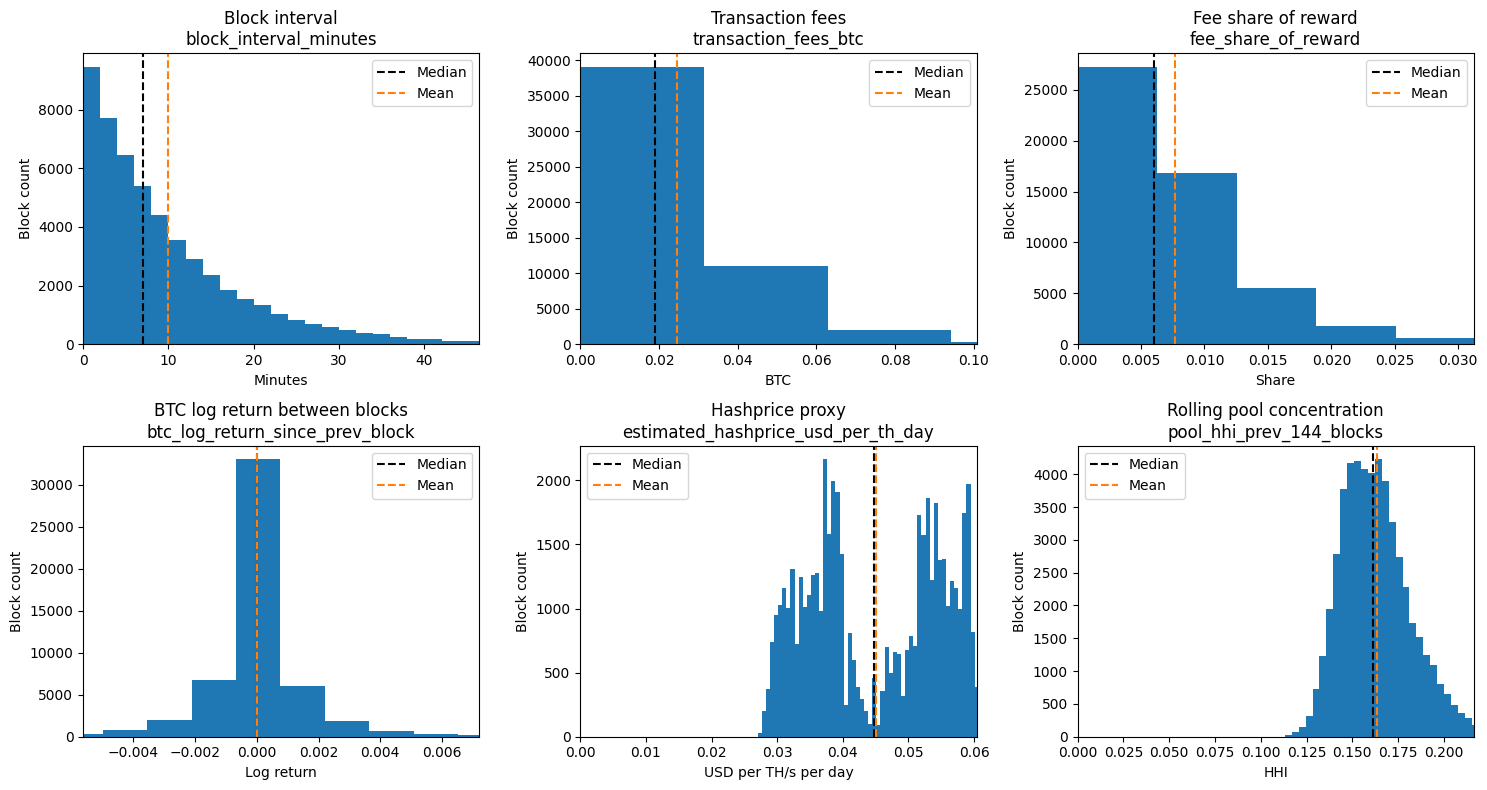

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()

plot_specs = [
    ("block_interval_minutes", "Block interval", "Minutes", 0.99),
    ("transaction_fees_btc", "Transaction fees", "BTC", 0.99),
    ("fee_share_of_reward", "Fee share of reward", "Share", 0.99),
    ("btc_log_return_since_prev_block", "BTC log return between blocks", "Log return", 0.995),
    ("estimated_hashprice_usd_per_th_day", "Hashprice proxy", "USD per TH/s per day", 0.99),
    ("pool_hhi_prev_144_blocks", "Rolling pool concentration", "HHI", 0.99),
]

for ax, (col, title, xlabel, upper_quantile) in zip(axes, plot_specs):
    series = blocks_clean[col].dropna()
    lower = series.quantile(0.01) if series.min() < 0 else 0
    upper = series.quantile(upper_quantile)
    ax.hist(series, bins=60)
    ax.axvline(series.median(), linestyle="--", color="black", label="Median")
    ax.axvline(series.mean(), linestyle="--", color="tab:orange", label="Mean")
    ax.set_xlim(lower, upper)
    ax.set_title(f"{title}\n{col}")
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Block count")
    ax.legend()

plt.tight_layout()
plt.show()


### 2.4.3 How To Use These Distributions In The MAS

| Distribution | What it measures | Exact MAS use | Added value |
|---|---|---|---|
| `block_interval_minutes` | Time between consecutive blocks | Sample simulated round duration or validate block discovery timing | Replaces fixed 10-minute steps with realistic stochastic timing |
| `transaction_fees_btc` | Fee component of each block reward | Sample the fee added to the block subsidy when a block is found | Makes miner revenue variable instead of constant |
| `fee_share_of_reward` | Fees as a share of total miner reward | Define low-fee, normal-fee, and high-fee market regimes | Shows when fees materially affect miner incentives |
| `btc_log_return_since_prev_block` | BTC price movement between blocks | Drive exogenous price shocks between simulation rounds | Models market volatility without giving agents future prices |
| `estimated_hashprice_usd_per_th_day` | Public revenue pressure per TH/s/day | Combine later with agent electricity and hardware costs for activation decisions | Converts price, reward, difficulty, and hashrate into one mining profitability signal |
| `pool_hhi_prev_144_blocks` | Rolling mining-pool concentration | Validate simulated decentralization or concentration | Checks whether agent/pool structure produces realistic market concentration |


### 2.4.4 Pool Block-Share Distribution

`winning_pool` does not reveal individual miners. It reveals the pool that mined each block. This distribution is useful when MAS agents represent pools, or when pool shares are used as validation targets for simulated winners.


,pool_share_percent
count,34.000000
mean,2.941176
std,6.201026
min,0.001899
50%,0.307581
75%,2.033454
90%,10.116957
95%,13.582278
99%,25.620802
max,29.484137


,blocks_mined,share_percent
winning_pool,,
Foundry USA,15529,29.484137
AntPool,9363,17.777061
ViaBTC,5964,11.323549
F2Pool,5756,10.928630
SpiderPool,4331,8.223053
MARA Pool,2578,4.894720
SECPOOL,2011,3.818185
Luxor,1776,3.372003
Binance Pool,1124,2.134083


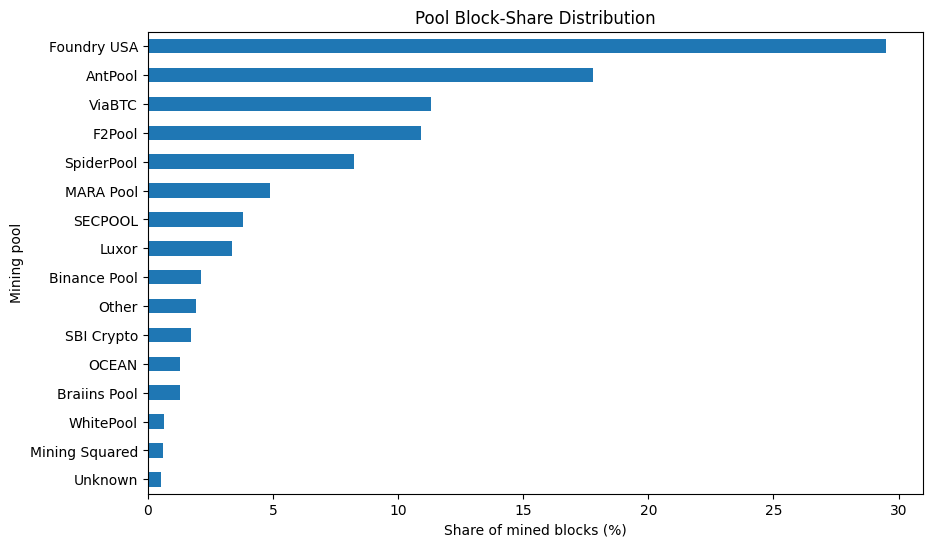

In [16]:
pool_counts = blocks_clean["winning_pool"].value_counts()
pool_share_distribution = pd.DataFrame({
    "blocks_mined": pool_counts,
    "share_percent": pool_counts / pool_counts.sum() * 100,
})

pool_share_summary = pool_share_distribution["share_percent"].describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]).to_frame("pool_share_percent")
display(pool_share_summary)
display(pool_share_distribution.head(20))

top_n = 15
top_pool_shares = pool_share_distribution.head(top_n).copy()
other = pool_share_distribution.iloc[top_n:].sum(numeric_only=True)
if other["blocks_mined"] > 0:
    top_pool_shares.loc["Other"] = other

plt.figure(figsize=(10, 6))
top_pool_shares["share_percent"].sort_values().plot(kind="barh")
plt.xlabel("Share of mined blocks (%)")
plt.ylabel("Mining pool")
plt.title("Pool Block-Share Distribution")
plt.show()


### 2.4.5 Pool-Level Hashrate Proxy

Public block data cannot identify hashrate per individual miner. It can estimate a **pool-level hashrate proxy** from the pool's observed share of discovered blocks:

```text
estimated_pool_hashrate_th_s = pool_block_share * average_network_hashrate_th_s
```

This is useful if MAS agents are mining pools. If MAS agents are individual miners, this proxy should be split across miners using a separate scenario assumption, for example a lognormal or Pareto distribution.


,blocks_mined,share_percent,estimated_pool_hashrate_th_s,estimated_pool_hashrate_eh_s
winning_pool,,,,
Foundry USA,15529,29.484137,2.895062e+08,289.506203
AntPool,9363,17.777061,1.745538e+08,174.553840
ViaBTC,5964,11.323549,1.111865e+08,111.186489
F2Pool,5756,10.928630,1.073088e+08,107.308758
SpiderPool,4331,8.223053,8.074257e+07,80.742570
MARA Pool,2578,4.894720,4.806150e+07,48.061497
SECPOOL,2011,3.818185,3.749095e+07,37.490951
Luxor,1776,3.372003,3.310986e+07,33.109860
Binance Pool,1124,2.134083,2.095466e+07,20.954664


,winning_pool_hashrate_proxy_eh_s
count,52669.000000
mean,154.295175
std,105.598080
min,0.000000
5%,7.498272
25%,68.824390
50%,133.048837
75%,244.802148
95%,333.055915
max,468.655535


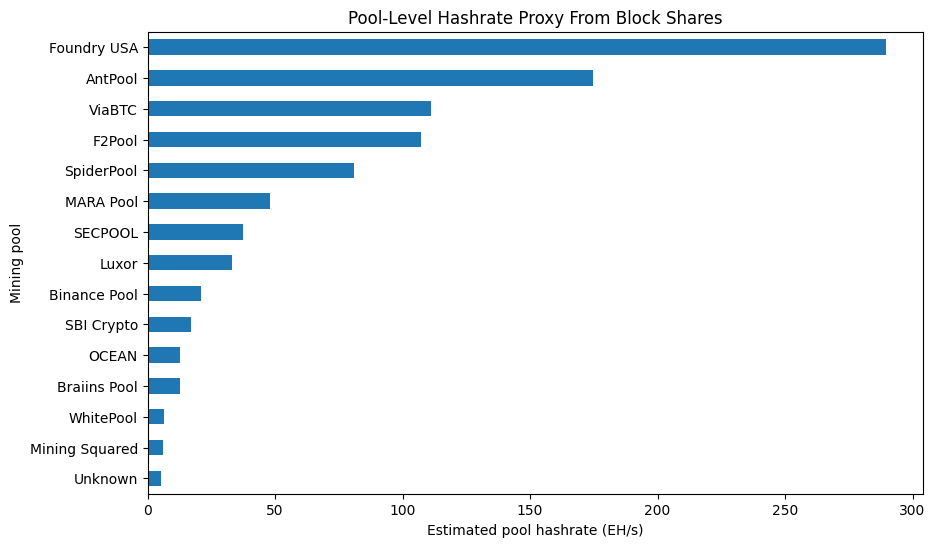

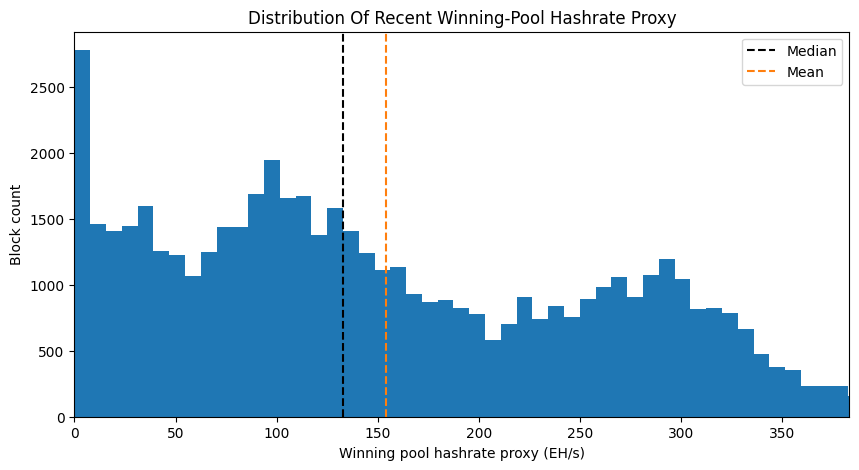

In [17]:
avg_network_hashrate_th_s = blocks_clean["estimated_network_hashrate_th_s"].mean()

pool_hashrate_proxy = pool_share_distribution.copy()
pool_hashrate_proxy["estimated_pool_hashrate_th_s"] = (
    pool_hashrate_proxy["share_percent"] / 100 * avg_network_hashrate_th_s
)
pool_hashrate_proxy["estimated_pool_hashrate_eh_s"] = (
    pool_hashrate_proxy["estimated_pool_hashrate_th_s"] / 1_000_000
)

# Recent hashrate proxy for the winning pool at each block, based on the previous 144 blocks.
blocks_clean["winning_pool_hashrate_proxy_th_s"] = (
    blocks_clean["winning_pool_share_prev_144_blocks"]
    * blocks_clean["estimated_network_hashrate_th_s"]
)
blocks_clean["winning_pool_hashrate_proxy_eh_s"] = blocks_clean["winning_pool_hashrate_proxy_th_s"] / 1_000_000

hashrate_proxy_summary = blocks_clean["winning_pool_hashrate_proxy_eh_s"].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
).to_frame("winning_pool_hashrate_proxy_eh_s")

display(pool_hashrate_proxy.head(20))
display(hashrate_proxy_summary)

plt.figure(figsize=(10, 6))
pool_hashrate_proxy.head(top_n)["estimated_pool_hashrate_eh_s"].sort_values().plot(kind="barh")
plt.xlabel("Estimated pool hashrate (EH/s)")
plt.ylabel("Mining pool")
plt.title("Pool-Level Hashrate Proxy From Block Shares")
plt.show()

plt.figure(figsize=(10, 5))
series = blocks_clean["winning_pool_hashrate_proxy_eh_s"].dropna()
plt.hist(series, bins=60)
plt.axvline(series.median(), linestyle="--", color="black", label="Median")
plt.axvline(series.mean(), linestyle="--", color="tab:orange", label="Mean")
plt.xlim(0, series.quantile(0.99))
plt.xlabel("Winning pool hashrate proxy (EH/s)")
plt.ylabel("Block count")
plt.title("Distribution Of Recent Winning-Pool Hashrate Proxy")
plt.legend()
plt.show()


### 2.4.6 Fitted Distributions And Goodness-Of-Fit Tests

The histograms show the empirical shape. This subsection fits candidate statistical distributions to the same variables and compares them with AIC, BIC, Kolmogorov-Smirnov (KS), and Cramer-von Mises (CvM) diagnostics.

Important interpretation rules:
- AIC/BIC compare candidate distributions for the same variable. Lower is better.
- KS and CvM test whether the fitted distribution exactly matches the data. With more than 50,000 blocks, even tiny deviations can produce very small p-values.
- Because parameters are estimated from the same data, KS/CvM p-values are approximate diagnostics, not final proof.
- If all simple parametric fits are rejected, use empirical sampling from the observed data or a scenario-specific mixture model in the MAS.


In [18]:
from scipy import stats


def _format_params(params):
    return ", ".join(f"{value:.6g}" for value in params)


def fit_candidate_distributions(series, variable_name, candidates, positive_only=False):
    x = pd.Series(series).replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    original_n = len(x)
    if positive_only:
        x = x[x > 0]

    values = x.to_numpy()
    rows = []

    for distribution_name, distribution, fit_kwargs in candidates:
        try:
            params = distribution.fit(values, **fit_kwargs)
            logpdf = distribution.logpdf(values, *params)
            log_likelihood = float(np.sum(logpdf[np.isfinite(logpdf)]))
            parameter_count = len(params)
            n = len(values)

            aic = 2 * parameter_count - 2 * log_likelihood
            bic = np.log(n) * parameter_count - 2 * log_likelihood
            cdf = lambda observed, dist=distribution, fitted=params: dist.cdf(observed, *fitted)
            ks_statistic, ks_p_value = stats.kstest(values, cdf)
            cvm_result = stats.cramervonmises(values, cdf)

            rows.append({
                "variable": variable_name,
                "distribution": distribution_name,
                "n_used": n,
                "dropped_nonpositive": original_n - n,
                "log_likelihood": log_likelihood,
                "aic": aic,
                "bic": bic,
                "ks_statistic": ks_statistic,
                "ks_p_value": ks_p_value,
                "cvm_statistic": cvm_result.statistic,
                "cvm_p_value": cvm_result.pvalue,
                "params": _format_params(params),
                "fitted_params": params,
                "distribution_object": distribution,
                "error": None,
            })
        except Exception as exc:
            rows.append({
                "variable": variable_name,
                "distribution": distribution_name,
                "n_used": len(values),
                "dropped_nonpositive": original_n - len(values),
                "log_likelihood": np.nan,
                "aic": np.nan,
                "bic": np.nan,
                "ks_statistic": np.nan,
                "ks_p_value": np.nan,
                "cvm_statistic": np.nan,
                "cvm_p_value": np.nan,
                "params": None,
                "fitted_params": None,
                "distribution_object": distribution,
                "error": str(exc),
            })

    return pd.DataFrame(rows).sort_values("aic")


# Use unique market-price updates for BTC returns. Block-level repeated prices create an artificial spike at zero.
price_updates = (
    blocks_clean
    .drop_duplicates("price_time")
    .sort_values("price_time")
    .copy()
)
price_updates["btc_log_return_per_price_update"] = np.log(
    price_updates["btc_price_at_block"] / price_updates["btc_price_at_block"].shift(1)
)

positive_candidates = [
    ("exponential", stats.expon, {"floc": 0}),
    ("gamma", stats.gamma, {"floc": 0}),
    ("weibull_min", stats.weibull_min, {"floc": 0}),
    ("lognormal", stats.lognorm, {"floc": 0}),
]

return_candidates = [
    ("normal", stats.norm, {}),
    ("student_t", stats.t, {}),
    ("logistic", stats.logistic, {}),
]

bounded_candidates = [
    ("beta_0_1", stats.beta, {"floc": 0, "fscale": 1}),
    ("normal", stats.norm, {}),
    ("gamma", stats.gamma, {"floc": 0}),
    ("lognormal", stats.lognorm, {"floc": 0}),
]

fit_specs = [
    ("block_interval_minutes", blocks_clean["block_interval_minutes"], positive_candidates, True, "Minutes"),
    ("transaction_fees_btc", blocks_clean["transaction_fees_btc"], positive_candidates, True, "BTC"),
    ("fee_share_of_reward", blocks_clean["fee_share_of_reward"], bounded_candidates, True, "Share"),
    ("btc_log_return_per_price_update", price_updates["btc_log_return_per_price_update"], return_candidates, False, "Log return"),
    ("estimated_hashprice_usd_per_th_day", blocks_clean["estimated_hashprice_usd_per_th_day"], positive_candidates, True, "USD per TH/s per day"),
    ("pool_hhi_prev_144_blocks", blocks_clean["pool_hhi_prev_144_blocks"], bounded_candidates, True, "HHI"),
    ("winning_pool_hashrate_proxy_eh_s", blocks_clean["winning_pool_hashrate_proxy_eh_s"], positive_candidates, True, "EH/s"),
]

fit_result_frames = []
fit_series_by_variable = {}
fit_axis_labels = {}

for variable_name, series, candidates, positive_only, axis_label in fit_specs:
    results = fit_candidate_distributions(series, variable_name, candidates, positive_only=positive_only)
    fit_result_frames.append(results)

    cleaned = pd.Series(series).replace([np.inf, -np.inf], np.nan).dropna().astype(float)
    if positive_only:
        cleaned = cleaned[cleaned > 0]
    fit_series_by_variable[variable_name] = cleaned
    fit_axis_labels[variable_name] = axis_label

fit_results = pd.concat(fit_result_frames, ignore_index=True)
display_cols = [
    "variable", "distribution", "n_used", "dropped_nonpositive",
    "aic", "bic", "ks_statistic", "ks_p_value",
    "cvm_statistic", "cvm_p_value", "params", "error",
]

best_fits = (
    fit_results
    .dropna(subset=["aic"])
    .sort_values(["variable", "aic"])
    .groupby("variable", as_index=False)
    .first()
)
best_fits["goodness_of_fit_interpretation"] = np.where(
    (best_fits["ks_p_value"] >= 0.05) & (best_fits["cvm_p_value"] >= 0.05),
    "Parametric fit is acceptable as a MAS sampling candidate",
    "Exact simple fit rejected; prefer empirical sampling, rolling regimes, or a mixture model",
)

display(best_fits[display_cols])
display(best_fits[["variable", "distribution", "goodness_of_fit_interpretation"]])
display(fit_results.sort_values(["variable", "aic"])[display_cols])


,variable,distribution,n_used,dropped_nonpositive,aic,bic,ks_statistic,ks_p_value,cvm_statistic,cvm_p_value,params,error
0,block_interval_minutes,gamma,52659,10,347579.861099,347606.475877,0.005385,9.400898e-02,0.307284,1.289511e-01,"1.03283, 0, 9.66261",None
1,btc_log_return_per_price_update,student_t,33400,0,-323833.776485,-323808.527551,0.005096,3.496685e-01,0.219940,2.319548e-01,"1.99141, -1.14557e-05, 0.00113187",None
2,estimated_hashprice_usd_per_th_day,weibull_min,52669,0,-337073.859114,-337047.243767,0.149519,0.000000e+00,285.998484,8.469397e-08,"5.22248, 0, 0.0490108",None
3,fee_share_of_reward,gamma,52576,93,-410676.268290,-410649.658245,0.019326,1.727709e-17,4.530068,3.767864e-11,"1.47636, 0, 0.00522741",None
4,pool_hhi_prev_144_blocks,lognormal,52669,0,-269962.242314,-269935.626967,0.027875,5.487750e-36,13.756384,4.167504e-10,"0.115028, 0, 0.162149",None
5,transaction_fees_btc,gamma,52576,93,-288774.822483,-288748.212437,0.021660,7.390738e-22,6.082045,1.035172e-11,"1.44722, 0, 0.016934",None
6,winning_pool_hashrate_proxy_eh_s,weibull_min,51334,1335,613342.463443,613369.001768,0.066776,1.840436e-199,47.354177,2.342542e-08,"1.46122, 0, 173.947",None


,variable,distribution,goodness_of_fit_interpretation
0,block_interval_minutes,gamma,Parametric fit is acceptable as a MAS sampling...
1,btc_log_return_per_price_update,student_t,Parametric fit is acceptable as a MAS sampling...
2,estimated_hashprice_usd_per_th_day,weibull_min,Exact simple fit rejected; prefer empirical sa...
3,fee_share_of_reward,gamma,Exact simple fit rejected; prefer empirical sa...
4,pool_hhi_prev_144_blocks,lognormal,Exact simple fit rejected; prefer empirical sa...
5,transaction_fees_btc,gamma,Exact simple fit rejected; prefer empirical sa...
6,winning_pool_hashrate_proxy_eh_s,weibull_min,Exact simple fit rejected; prefer empirical sa...


,variable,distribution,n_used,dropped_nonpositive,aic,bic,ks_statistic,ks_p_value,cvm_statistic,cvm_p_value,params,error
0,block_interval_minutes,gamma,52659,10,347579.861099,347606.475877,0.005385,9.400898e-02,0.307284,1.289511e-01,"1.03283, 0, 9.66261",None
1,block_interval_minutes,weibull_min,52659,10,347594.480694,347621.095471,0.004451,2.469906e-01,0.229852,2.163907e-01,"1.01542, 0, 10.0441",None
2,block_interval_minutes,exponential,52659,10,347612.781831,347630.525016,0.006624,1.958871e-02,0.465067,4.891472e-02,"0, 9.97981",None
3,block_interval_minutes,lognormal,52659,10,354907.704591,354934.319368,0.069117,3.533001e-219,91.044695,2.095201e-08,"1.23009, 0, 5.71897",None
12,btc_log_return_per_price_update,student_t,33400,0,-323833.776485,-323808.527551,0.005096,3.496685e-01,0.219940,2.319548e-01,"1.99141, -1.14557e-05, 0.00113187",None
13,btc_log_return_per_price_update,logistic,33400,0,-319671.421510,-319654.588888,0.049505,1.417040e-71,34.949810,8.679793e-09,"-1.19709e-06, 0.00107948",None
14,btc_log_return_per_price_update,normal,33400,0,-309966.118023,-309949.285400,0.104582,1.558639e-318,167.095448,4.168832e-08,"-5.13175e-06, 0.00233625",None
15,estimated_hashprice_usd_per_th_day,weibull_min,52669,0,-337073.859114,-337047.243767,0.149519,0.000000e+00,285.998484,8.469397e-08,"5.22248, 0, 0.0490108",None
16,estimated_hashprice_usd_per_th_day,gamma,52669,0,-336273.830667,-336247.215320,0.143184,0.000000e+00,280.121662,6.429775e-08,"19.8072, 0, 0.00227152",None
17,estimated_hashprice_usd_per_th_day,lognormal,52669,0,-335634.275640,-335607.660293,0.148265,0.000000e+00,277.839203,1.091542e-07,"0.227971, 0, 0.0438616",None


### 2.4.7 Fitted Distribution Overlays

The plots below overlay the best AIC distribution on top of the empirical histogram. A good MAS input distribution should match both the central mass and the tail behavior. If the overlay misses the tail or has a very small goodness-of-fit p-value, empirical sampling is usually safer.


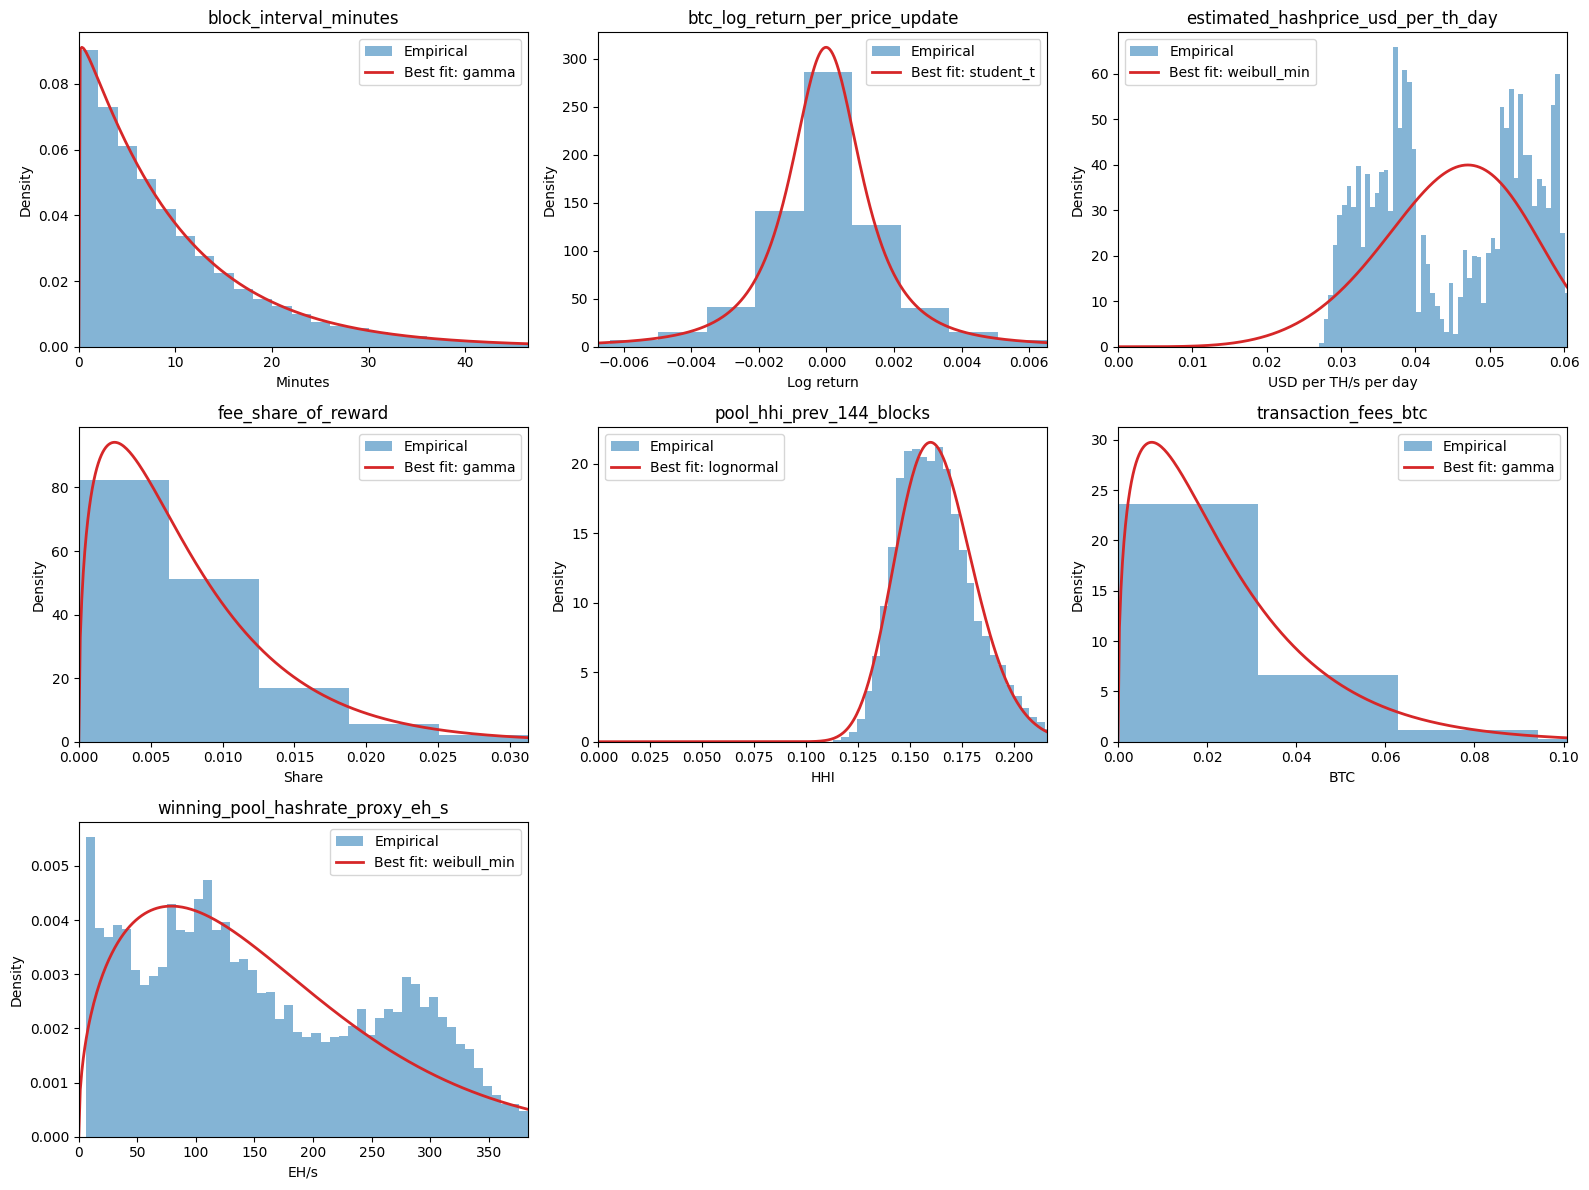

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.ravel()

for ax, (_, best_fit) in zip(axes, best_fits.iterrows()):
    variable_name = best_fit["variable"]
    series = fit_series_by_variable[variable_name]
    distribution = best_fit["distribution_object"]
    params = best_fit["fitted_params"]

    lower = series.quantile(0.01) if series.min() < 0 else 0
    upper = series.quantile(0.99)
    grid = np.linspace(lower, upper, 300)

    ax.hist(series, bins=60, density=True, alpha=0.55, label="Empirical")
    ax.plot(grid, distribution.pdf(grid, *params), color="tab:red", linewidth=2, label=f"Best fit: {best_fit['distribution']}")
    ax.set_xlim(lower, upper)
    ax.set_title(variable_name)
    ax.set_xlabel(fit_axis_labels[variable_name])
    ax.set_ylabel("Density")
    ax.legend()

for ax in axes[len(best_fits):]:
    ax.axis("off")

plt.tight_layout()
plt.show()


### 2.4.8 Pool Winner Distribution Stability Test

Pool winners are categorical, so they should not be fitted with a continuous distribution. Instead, this test checks whether the observed pool-winner distribution is stable between the first and second half of the sample.

A small p-value means the pool distribution changed over time. In that case, the MAS should avoid one fixed pool-share vector and should instead use rolling shares, changing hashrate shares, or scenario regimes.


In [20]:
top_pools_for_test = pool_counts.head(10).index
pool_test = blocks_clean[["block_time", "winning_pool"]].copy()
pool_test["pool_group"] = np.where(
    pool_test["winning_pool"].isin(top_pools_for_test),
    pool_test["winning_pool"],
    "Other",
)
pool_test["sample_period"] = np.where(
    pool_test["block_time"] <= pool_test["block_time"].median(),
    "first_half",
    "second_half",
)

pool_contingency = pd.crosstab(pool_test["sample_period"], pool_test["pool_group"])
chi2_statistic, chi2_p_value, chi2_dof, expected_counts = stats.chi2_contingency(pool_contingency)

pool_stability_test = pd.Series({
    "test": "Chi-square test of homogeneity",
    "null_hypothesis": "Pool winner shares are the same in both halves of the sample",
    "chi2_statistic": chi2_statistic,
    "degrees_of_freedom": chi2_dof,
    "p_value": chi2_p_value,
    "interpretation": "Reject stable pool shares" if chi2_p_value < 0.05 else "No strong evidence of changing pool shares",
})

display(pool_contingency)
display(pool_stability_test.to_frame("value"))


pool_group,AntPool,Binance Pool,F2Pool,Foundry USA,Luxor,MARA Pool,Other,SBI Crypto,SECPOOL,SpiderPool,ViaBTC
sample_period,,,,,,,,,,,
first_half,4739,493,2829,7692,978,1272,1747,442,859,2061,3223
second_half,4624,631,2927,7837,798,1306,1578,470,1152,2270,2741


,value
test,Chi-square test of homogeneity
null_hypothesis,Pool winner shares are the same in both halves...
chi2_statistic,141.248792
degrees_of_freedom,10
p_value,0.0
interpretation,Reject stable pool shares


## 2.5 Block Arrival Process

Bitcoin block times are stochastic. The important MAS target is not only the average near 10 minutes, but also the long right tail of waiting times.


,minutes
count,52669.000000
mean,9.977913
std,9.951523
min,0.000000
1%,0.150000
5%,0.550000
25%,2.916667
50%,6.966667
75%,13.700000
95%,29.893333


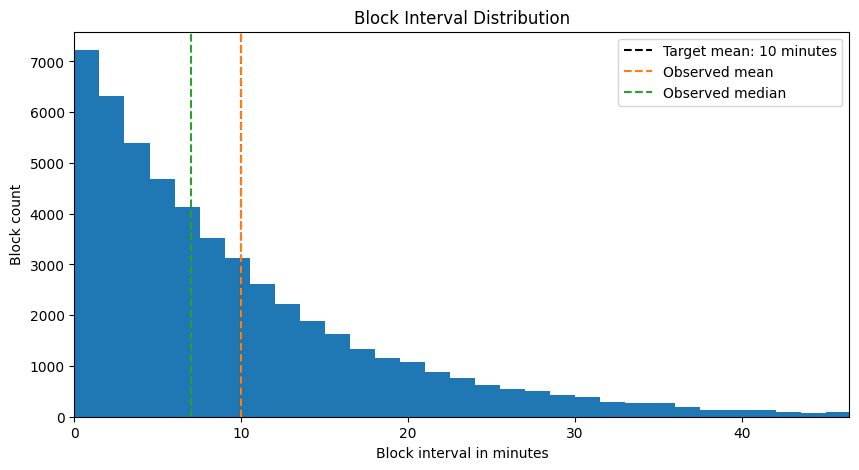

In [21]:
block_interval_summary = blocks_clean["block_interval_minutes"].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).to_frame("minutes")
display(block_interval_summary)

plt.figure(figsize=(10, 5))
plt.hist(blocks_clean["block_interval_minutes"], bins=80)
plt.axvline(10, linestyle="--", color="black", label="Target mean: 10 minutes")
plt.axvline(blocks_clean["block_interval_minutes"].mean(), linestyle="--", color="tab:orange", label="Observed mean")
plt.axvline(blocks_clean["block_interval_minutes"].median(), linestyle="--", color="tab:green", label="Observed median")
plt.xlim(0, blocks_clean["block_interval_minutes"].quantile(0.99))
plt.xlabel("Block interval in minutes")
plt.ylabel("Block count")
plt.title("Block Interval Distribution")
plt.legend()
plt.show()


## 2.6 Reward And Fee Environment

The MAS can use the block subsidy as the stable reward component and transaction fees as the volatile component. USD values depend on the public BTC price at the latest completed market candle.


,count,mean,std,min,5%,50%,95%,max
block_reward_btc,52669.0,3.125000,0.000000,3.125000,3.125000,3.125000,3.125000,3.125000
transaction_fees_btc,52669.0,0.024464,0.026433,0.000000,0.002893,0.018995,0.062722,1.885815
total_reward_btc,52669.0,3.149464,0.026433,3.125000,3.127893,3.143995,3.187722,5.010815
transaction_fees_usd,52669.0,2437.845946,2843.192143,0.000000,246.057526,1783.975020,6615.376724,198854.220213
total_reward_usd,52669.0,303652.290849,56052.055512,196157.890468,211335.291578,324505.157397,374572.186570,528377.313963
fee_share_of_reward,52669.0,0.007704,0.007657,0.000000,0.000925,0.006042,0.019676,0.376349


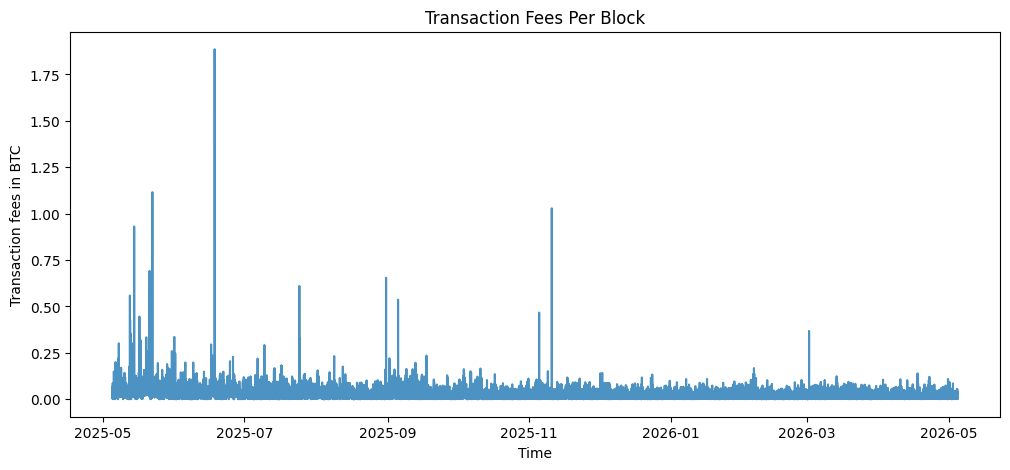

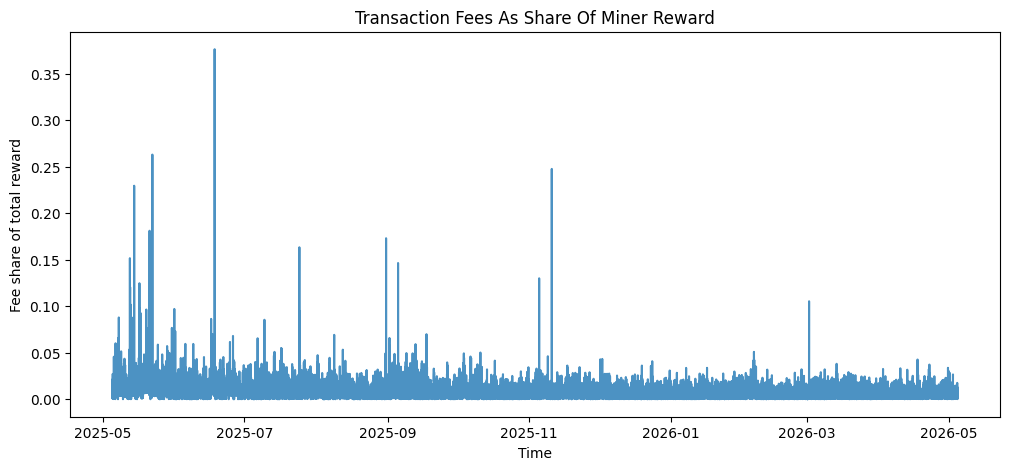

In [22]:
reward_cols = [
    "block_reward_btc",
    "transaction_fees_btc",
    "total_reward_btc",
    "transaction_fees_usd",
    "total_reward_usd",
    "fee_share_of_reward",
]

reward_summary = blocks_clean[reward_cols].describe(percentiles=[0.05, 0.5, 0.95]).T
display(reward_summary)

plt.figure(figsize=(12, 5))
plt.plot(blocks_clean["block_time"], blocks_clean["transaction_fees_btc"], alpha=0.8)
plt.xlabel("Time")
plt.ylabel("Transaction fees in BTC")
plt.title("Transaction Fees Per Block")
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(blocks_clean["block_time"], blocks_clean["fee_share_of_reward"], alpha=0.8)
plt.xlabel("Time")
plt.ylabel("Fee share of total reward")
plt.title("Transaction Fees As Share Of Miner Reward")
plt.show()


## 2.7 Mining Pool Structure

Pool shares are useful validation targets for the MAS. If simulated winners are much more concentrated or fragmented than these public observations, the agent population or hashrate allocation probably needs adjustment.


,blocks_mined,share_percent
winning_pool,,
Foundry USA,15529,29.484137
AntPool,9363,17.777061
ViaBTC,5964,11.323549
F2Pool,5756,10.928630
SpiderPool,4331,8.223053
MARA Pool,2578,4.894720
SECPOOL,2011,3.818185
Luxor,1776,3.372003
Binance Pool,1124,2.134083


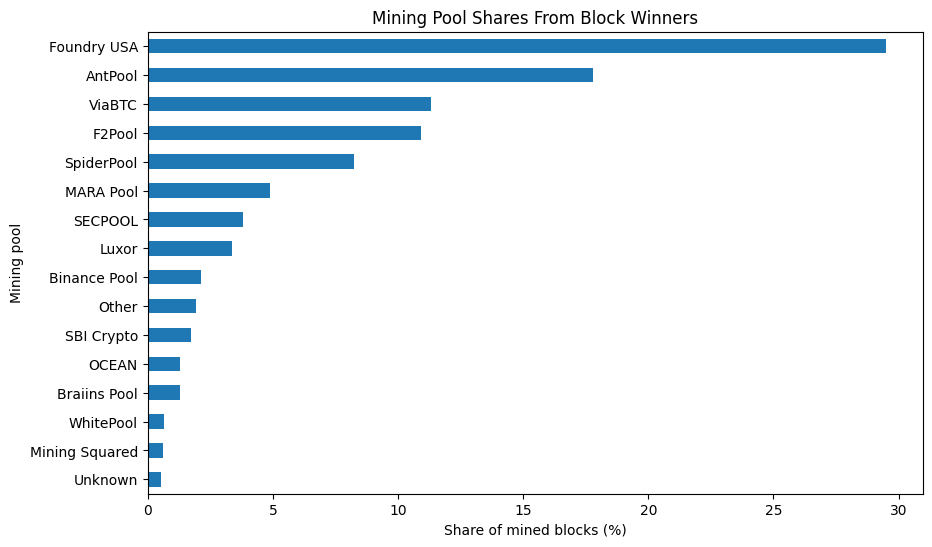

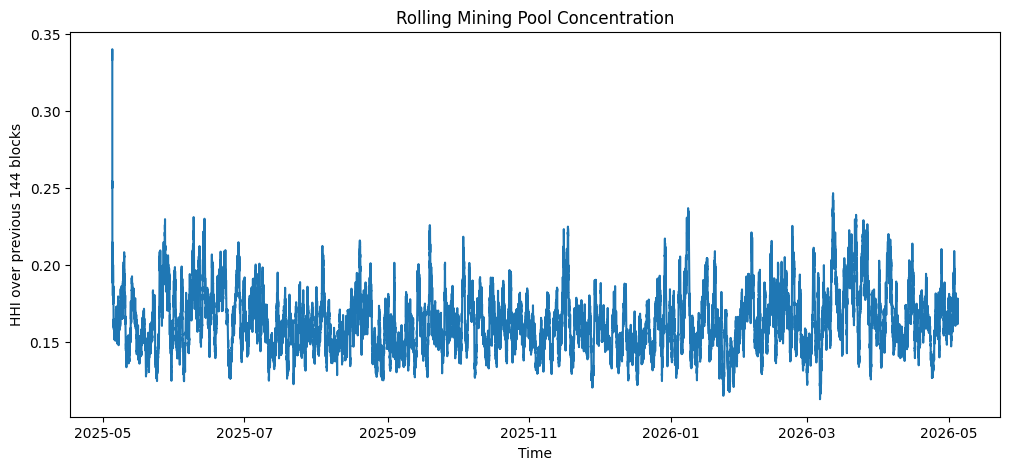

In [23]:
top_n = 15
pool_counts = blocks_clean["winning_pool"].value_counts()
pool_share_table = pd.DataFrame({
    "blocks_mined": pool_counts,
    "share_percent": pool_counts / pool_counts.sum() * 100,
})

top_pool_plot = pool_share_table.head(top_n).copy()
other_share = pool_share_table.iloc[top_n:]["share_percent"].sum()
other_blocks = pool_share_table.iloc[top_n:]["blocks_mined"].sum()
if other_blocks > 0:
    top_pool_plot.loc["Other"] = [other_blocks, other_share]

display(pool_share_table.head(20))

plt.figure(figsize=(10, 6))
top_pool_plot["share_percent"].sort_values().plot(kind="barh")
plt.xlabel("Share of mined blocks (%)")
plt.ylabel("Mining pool")
plt.title("Mining Pool Shares From Block Winners")
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(blocks_clean["block_time"], blocks_clean["pool_hhi_prev_144_blocks"])
plt.xlabel("Time")
plt.ylabel("HHI over previous 144 blocks")
plt.title("Rolling Mining Pool Concentration")
plt.show()


## 2.8 Market And Network Context

These public variables describe the external environment agents are operating in. They are useful as exogenous inputs or validation targets, depending on the MAS design.


,blocks_per_day,btc_price_at_block,estimated_hashprice_usd_per_th_day,estimated_network_hashrate_th_s,network_difficulty,pool_hhi_prev_144_blocks,transaction_fees_btc
block_time,,,,,,,
2025-05-05 00:00:00+00:00,166,94425.648735,0.050238,8.526674e+08,1.191163e+14,0.180322,0.029975
2025-05-06 00:00:00+00:00,138,94528.418116,0.050428,8.526674e+08,1.191163e+14,0.160597,0.037892
2025-05-07 00:00:00+00:00,151,96871.597748,0.051793,8.526674e+08,1.191163e+14,0.160989,0.044031
2025-05-08 00:00:00+00:00,159,100007.621132,0.053508,8.526674e+08,1.191163e+14,0.169571,0.041142
2025-05-09 00:00:00+00:00,140,103011.711643,0.055168,8.526674e+08,1.191163e+14,0.183015,0.049051


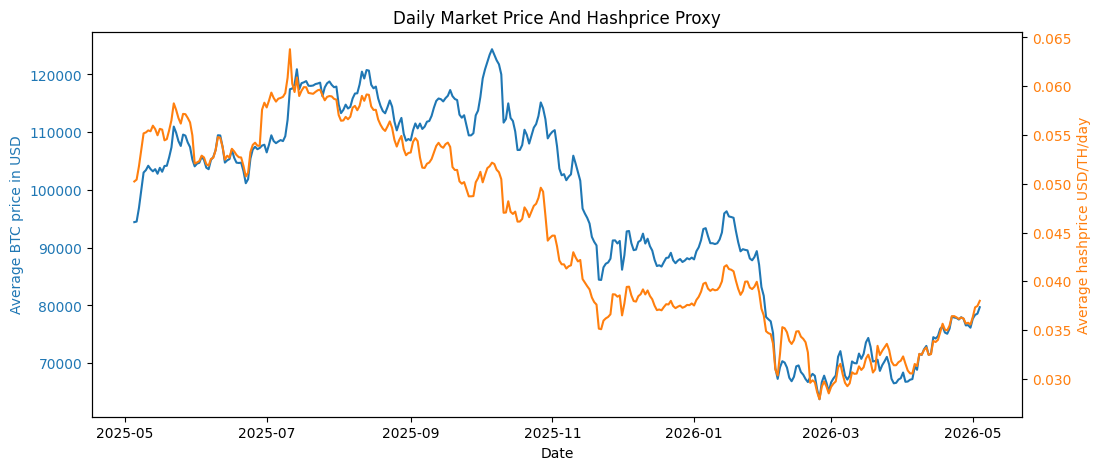

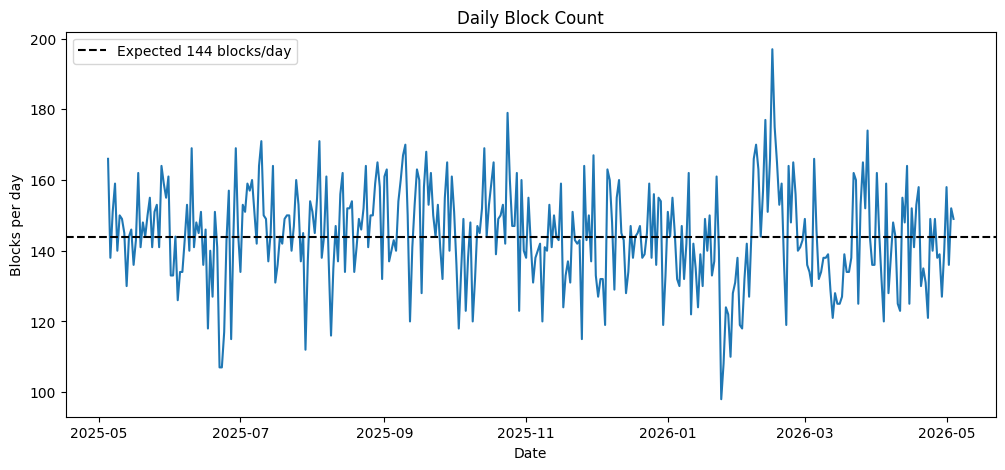

In [24]:
daily_context = (
    blocks_clean
    .set_index("block_time")
    .resample("1D")
    .agg({
        "block_height": "count",
        "btc_price_at_block": "mean",
        "estimated_hashprice_usd_per_th_day": "mean",
        "estimated_network_hashrate_th_s": "mean",
        "network_difficulty": "mean",
        "pool_hhi_prev_144_blocks": "mean",
        "transaction_fees_btc": "mean",
    })
    .rename(columns={"block_height": "blocks_per_day"})
)

display(daily_context.head())

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(daily_context.index, daily_context["btc_price_at_block"], color="tab:blue")
ax1.set_xlabel("Date")
ax1.set_ylabel("Average BTC price in USD", color="tab:blue")
ax1.tick_params(axis="y", labelcolor="tab:blue")

ax2 = ax1.twinx()
ax2.plot(daily_context.index, daily_context["estimated_hashprice_usd_per_th_day"], color="tab:orange")
ax2.set_ylabel("Average hashprice USD/TH/day", color="tab:orange")
ax2.tick_params(axis="y", labelcolor="tab:orange")

plt.title("Daily Market Price And Hashprice Proxy")
plt.show()

plt.figure(figsize=(12, 5))
plt.plot(daily_context.index, daily_context["blocks_per_day"])
plt.axhline(144, linestyle="--", color="black", label="Expected 144 blocks/day")
plt.xlabel("Date")
plt.ylabel("Blocks per day")
plt.title("Daily Block Count")
plt.legend()
plt.show()


## 2.9 Modeling Takeaways

The block-level dataset is most useful as a public calibration and validation layer for the MAS:

- Calibrate block timing from the empirical `block_interval_minutes` distribution.
- Calibrate reward variation from `transaction_fees_btc` and `fee_share_of_reward` rather than using a constant fee value.
- Use `btc_price_at_block`, `network_difficulty`, and `estimated_hashprice_usd_per_th_day` as external market and network conditions.
- Validate simulated pool concentration against observed winning-pool shares and rolling HHI.
- Keep electricity cost, hardware efficiency, and individual miner hashrate as MAS scenario assumptions. They are not observed in this public block-level dataset.


## 3. Historical Play-Through Multi-Agent System with Mining-Pool Archetypes

This section uses a historical play-through model. The historical block-level dataset drives the **environment**: BTC price, transaction fees, total reward, network difficulty, estimated network hashrate, and block interval are taken from the observed data.

The agents generate the **simulation outcome**. Instead of representing only the observed top pools, this version represents different **mining-pool archetypes**. This is useful because it makes the MAS more behavioral: large, efficient, low-cost pools do not have the same cost structure as smaller, less efficient pools.

The model still keeps block time historical in this base version. That means lower simulated active hashrate does **not yet** lengthen the block interval. This keeps the model suitable for validation against the observed block sequence. Endogenous block-time dynamics can be added later as a scenario extension.

In short:

- **Historical data drives the world.**
- **Mining-pool archetypes choose how much hashrate to allocate.**
- **The MAS generates simulated winners, allocation behavior, profit, and concentration.**
- **Observed winning pools are used for calibration and validation, not directly copied as simulated winners.**


### 3.1 Model assumptions

This implementation uses **synthetic pool-level archetype agents** with different kinds of mining pools can have different electricity costs, hardware efficiency, and scale.

The following variables are historical inputs:

| Variable | Role in MAS |
|---|---|
| `btc_price_at_block` | market price at block discovery |
| `transaction_fees_btc` | fee component of mining reward |
| `total_reward_btc` | subsidy plus transaction fees |
| `estimated_network_hashrate_th_s` | total network mining power proxy |
| `block_interval_minutes` | observed duration of the mining round |
| `winning_pool` | validation target, not the simulated winner |
| `pool_hhi_prev_144_blocks` | validation target for concentration |

Electricity price, hardware efficiency, and allocation behavior are **scenario assumptions** because they are not observed in this public block-level dataset.

The model uses four archetypes:

| Archetype | Intended interpretation | Number of agents | Relative size score |
|---|---|---:|---:|
| Type 1 | dominant low-cost pools | 1 | 240–300 |
| Type 2 | large efficient pools | 3 | 130–200 |
| Type 3 | lower/mid-scale pools | 1 | 65–90 |
| Type 4 | small outside-network pools | 29 | 6–20 |

Important: the size ranges above are used as **relative hashrate size scores**, not literal EH/s values. If they were literal EH/s values, the total would exceed the historical Bitcoin network hashrate. Therefore, the model samples relative size scores and normalizes them so all agents together represent 100% of the historical network hashrate.

Each pool chooses one of the following allocation levels:

| Allocation | Interpretation |
|---:|---|
| `0.0` | shut down for this block |
| `0.5` | scale back to 50% of baseline hashrate |
| `1.0` | mine at baseline hashrate |
| `1.1` | boost to 110% of baseline hashrate |

Electricity use is not modeled as perfectly linear. Scaling down is slightly more energy-efficient, while boosting is slightly less efficient. This prevents the decision rule from degenerating into only `0%` or `110%` behavior.


In [35]:
from dataclasses import dataclass, field
from datetime import timedelta
from pathlib import Path
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# This fallback allows Section 3 to run even when the earlier analysis cells
# have not been executed yet.
if "blocks_clean" not in globals():
    candidate_paths = [
        Path("block_level_market_data_20250505_20260505.csv"),
        Path("bitcoin_mining_data/final/block_level_market_data_20250505_20260505.csv"),
    ]
    candidate_paths.extend(sorted(Path(".").glob("block_level_market_data_*.csv"), reverse=True))
    candidate_paths.extend(sorted(Path("bitcoin_mining_data/final").glob("block_level_market_data_*.csv"), reverse=True))

    BLOCK_ANALYSIS_PATH = next((p for p in candidate_paths if p.exists()), None)
    if BLOCK_ANALYSIS_PATH is None:
        raise FileNotFoundError("Could not find a block_level_market_data CSV file.")

    blocks = pd.read_csv(BLOCK_ANALYSIS_PATH)
    blocks["block_time"] = pd.to_datetime(blocks["block_time"], utc=True)
    if "price_time" in blocks.columns:
        blocks["price_time"] = pd.to_datetime(blocks["price_time"], utc=True, errors="coerce")

    blocks["total_reward_usd"] = blocks["total_reward_btc"] * blocks["btc_price_at_block"]
    blocks["transaction_fees_usd"] = blocks["transaction_fees_btc"] * blocks["btc_price_at_block"]
    blocks["fee_share_of_reward"] = blocks["transaction_fees_btc"] / blocks["total_reward_btc"]

    model_cols = [
        "btc_price_at_block",
        "transaction_fees_btc",
        "total_reward_btc",
        "network_difficulty",
        "estimated_network_hashrate_th_s",
        "block_interval_minutes",
        "estimated_hashprice_usd_per_th_day",
    ]
    blocks_clean = blocks.dropna(subset=model_cols).sort_values("block_time").reset_index(drop=True)

historical_blocks = blocks_clean.sort_values("block_time").reset_index(drop=True).copy()
print(f"Historical environment blocks available: {len(historical_blocks):,}")

Historical environment blocks available: 52,669


### 3.2 Event logger and mining-pool agent

The event log is structured for later process mining. Each case represents one pool in one block round, for example `Foundry USA_block_895275`. This avoids mixing all agents into one unreadable process trace.

In [36]:
class ProcessLogger:
    def __init__(self):
        self.log = []
        self.event_counter = 0

    def add_event(self, step, case_id, activity, timestamp, **kwargs):
        self.event_counter += 1
        event = {
            "event_id": self.event_counter,
            "step": step,
            "case_id": case_id,
            "activity": activity,
            "timestamp": timestamp,
        }
        event.update(kwargs)
        self.log.append(event)

    def to_dataframe(self):
        return pd.DataFrame(self.log)


@dataclass
class MiningPoolAgent:
    name: str
    base_network_share: float
    electricity_price_usd_kwh: float
    efficiency_j_per_th: float
    agent_type: str = "Mining pool"
    force_active: bool = False
    allocation_options: tuple = (0.0, 0.5, 1.0, 1.1)
    boost_power_exponent: float = 1.08
    relative_size_score: float = np.nan
    reference_hashrate_eh_s: float = np.nan
    profit_usd: float = 0.0
    btc_balance: float = 0.0
    wins: int = 0
    active_rounds: int = 0
    evaluated_rounds: int = 0
    allocation_sum: float = 0.0
    allocated_hashrate_sum_th_s: float = 0.0
    electricity_cost_usd: float = 0.0
    realized_revenue_usd: float = 0.0

    def potential_hashrate_th_s(self, row):
        return self.base_network_share * float(row["estimated_network_hashrate_th_s"])

    def allocation_power_multiplier(self, allocation):
        """Translate hashrate allocation into power use.

        A value below 1.0 represents scaling back or underclocking. A value above
        1.0 represents boosting. The exponent makes boosting slightly less
        efficient and scaling down slightly more efficient than a perfectly
        linear power curve.
        """
        allocation = max(float(allocation), 0.0)
        if allocation == 0.0:
            return 0.0
        return allocation ** self.boost_power_exponent

    def allocated_hashrate_th_s(self, row, allocation):
        return self.potential_hashrate_th_s(row) * float(allocation)

    def power_kw(self, row, allocation):
        # TH/s * J/TH = W. Divide by 1000 to convert W to kW.
        base_power_kw = self.potential_hashrate_th_s(row) * self.efficiency_j_per_th / 1000.0
        return base_power_kw * self.allocation_power_multiplier(allocation)

    def _evaluate_allocation_rows(self, row):
        """Fast internal evaluator used by the simulation loop."""
        block_hours = max(float(row["block_interval_minutes"]), 0.0) / 60.0
        network_hashrate = max(float(row["estimated_network_hashrate_th_s"]), 1e-9)
        reward_usd = float(row["total_reward_btc"] * row["btc_price_at_block"])
        potential_hashrate = self.potential_hashrate_th_s(row)

        rows = []
        for allocation in self.allocation_options:
            allocation = float(allocation)
            allocated_hashrate = potential_hashrate * allocation
            power_kw = (potential_hashrate * self.efficiency_j_per_th / 1000.0) * self.allocation_power_multiplier(allocation)
            expected_win_probability = allocated_hashrate / network_hashrate
            expected_revenue = expected_win_probability * reward_usd
            expected_cost = power_kw * self.electricity_price_usd_kwh * block_hours
            expected_profit = expected_revenue - expected_cost
            rows.append(
                {
                    "allocation": allocation,
                    "allocated_hashrate_th_s": allocated_hashrate,
                    "power_kw": power_kw,
                    "expected_win_probability_vs_historical_network": expected_win_probability,
                    "expected_revenue_usd": expected_revenue,
                    "expected_cost_usd": expected_cost,
                    "expected_profit_usd": expected_profit,
                }
            )

        return rows

    def evaluate_allocation_options(self, row):
        """Return a table for inspecting the choices of one agent in one round."""
        return pd.DataFrame(self._evaluate_allocation_rows(row))

    def choose_hashrate_allocation(self, row):
        option_rows = self._evaluate_allocation_rows(row)

        if self.force_active:
            # This can be used for aggregate background agents. The current archetype
            # population does not require force-active agents, but the option is kept
            # for scenario testing.
            candidate_options = [r for r in option_rows if r["allocation"] > 0.0]
        else:
            candidate_options = option_rows

        best = max(candidate_options, key=lambda r: (r["expected_profit_usd"], r["allocation"]))

        active = bool(best["allocation"] > 0.0)
        return {
            "active": active,
            "selected_allocation": float(best["allocation"]),
            "potential_hashrate_th_s": self.potential_hashrate_th_s(row),
            "allocated_hashrate_th_s": float(best["allocated_hashrate_th_s"]),
            "power_kw": float(best["power_kw"]),
            "expected_win_probability_vs_historical_network": float(best["expected_win_probability_vs_historical_network"]),
            "expected_revenue_usd": float(best["expected_revenue_usd"]),
            "expected_cost_usd": float(best["expected_cost_usd"]),
            "expected_profit_usd": float(best["expected_profit_usd"]),
            "best_allocation_profit_usd": float(best["expected_profit_usd"]),
        }

    def register_decision(self, evaluation):
        self.evaluated_rounds += 1
        self.allocation_sum += float(evaluation["selected_allocation"])
        self.allocated_hashrate_sum_th_s += float(evaluation["allocated_hashrate_th_s"])
        if evaluation["active"]:
            self.active_rounds += 1

    def apply_realized_cost(self, row, allocation):
        block_hours = max(float(row["block_interval_minutes"]), 0.0) / 60.0
        cost = self.power_kw(row, allocation) * self.electricity_price_usd_kwh * block_hours
        self.profit_usd -= cost
        self.electricity_cost_usd += cost
        return cost

    def apply_reward(self, row):
        reward_btc = float(row["total_reward_btc"])
        reward_usd = float(row["total_reward_btc"] * row["btc_price_at_block"])
        self.btc_balance += reward_btc
        self.profit_usd += reward_usd
        self.realized_revenue_usd += reward_usd
        self.wins += 1
        return reward_btc, reward_usd


### 3.3 Build archetype agents

The archetype population creates four types of mining-pool agents. The size ranges are used as relative scores and then normalized to the historical network hashrate. This preserves the intended hierarchy while avoiding an impossible total network size.


In [43]:
def build_archetype_pool_agents(block_data, random_seed=42):
    """Create synthetic mining-pool agents by behavioral archetype.

    The relative_size_score values are not literal EH/s. They are sampled from
    the user's proposed hashrate bands and then normalized so that the full agent
    population represents one historical Bitcoin network.
    """
    rng = np.random.default_rng(random_seed)
    reference_network_hashrate_eh_s = float(block_data["estimated_network_hashrate_th_s"].median() / 1e6)
    allocation_options = (0.0, 0.5, 1.0, 1.1)

    archetype_specs = [
        {
            "agent_type": "Type 1: Dominant low-cost pools",
            "count": 1,
            "relative_size_range": (240, 300),
            "electricity_price_range": (0.030, 0.040),
            "efficiency_range_j_per_th": (19.0, 23.0),
        },
        {
            "agent_type": "Type 2: Large efficient pools",
            "count": 3,
            "relative_size_range": (130, 200),
            "electricity_price_range": (0.035, 0.052),
            "efficiency_range_j_per_th": (21.0, 25.0),
        },
        {
            "agent_type": "Type 3: Lower/mid-scale pools",
            "count": 1,
            "relative_size_range": (65, 90),
            "electricity_price_range": (0.052, 0.070),
            "efficiency_range_j_per_th": (25.0, 31.0),
        },
        {
            "agent_type": "Type 4: Small outside-network pools",
            "count": 29,
            "relative_size_range": (6, 20),
            "electricity_price_range": (0.035, 0.065),
            "efficiency_range_j_per_th": (24.0, 34.0),
        },
    ]

    raw_agents = []
    for spec in archetype_specs:
        for idx in range(1, spec["count"] + 1):
            relative_size_score = float(rng.uniform(*spec["relative_size_range"]))
            electricity_price = float(rng.uniform(*spec["electricity_price_range"]))
            efficiency = float(rng.uniform(*spec["efficiency_range_j_per_th"]))
            raw_agents.append(
                {
                    "name": f"{spec['agent_type'].split(':')[0]}_{idx:03d}",
                    "agent_type": spec["agent_type"],
                    "relative_size_score": relative_size_score,
                    "electricity_price_usd_kwh": electricity_price,
                    "efficiency_j_per_th": efficiency,
                }
            )

    total_relative_size = sum(a["relative_size_score"] for a in raw_agents)

    agents = []
    for raw_agent in raw_agents:
        base_network_share = raw_agent["relative_size_score"] / total_relative_size
        agents.append(
            MiningPoolAgent(
                name=raw_agent["name"],
                base_network_share=float(base_network_share),
                electricity_price_usd_kwh=raw_agent["electricity_price_usd_kwh"],
                efficiency_j_per_th=raw_agent["efficiency_j_per_th"],
                allocation_options=allocation_options,
                agent_type=raw_agent["agent_type"],
                relative_size_score=raw_agent["relative_size_score"],
                reference_hashrate_eh_s=base_network_share * reference_network_hashrate_eh_s,
            )
        )

    return agents


def summarize_agent_configuration(agents):
    return pd.DataFrame([
        {
            "name": a.name,
            "agent_type": a.agent_type,
            "base_network_share": a.base_network_share,
            "reference_hashrate_eh_s": a.reference_hashrate_eh_s,
            "relative_size_score": a.relative_size_score,
            "electricity_price_usd_kwh": a.electricity_price_usd_kwh,
            "efficiency_j_per_th": a.efficiency_j_per_th,
            "allocation_options": str(a.allocation_options),
            "boost_power_exponent": a.boost_power_exponent,
            "force_active": a.force_active,
        }
        for a in agents
    ])


agents_preview = build_archetype_pool_agents(historical_blocks, random_seed=42)
agent_configs = summarize_agent_configuration(agents_preview)
agent_type_config = (
    agent_configs
    .groupby("agent_type")
    .agg(
        agents=("name", "count"),
        total_base_network_share=("base_network_share", "sum"),
        mean_reference_hashrate_eh_s=("reference_hashrate_eh_s", "mean"),
        min_reference_hashrate_eh_s=("reference_hashrate_eh_s", "min"),
        max_reference_hashrate_eh_s=("reference_hashrate_eh_s", "max"),
        mean_electricity_price_usd_kwh=("electricity_price_usd_kwh", "mean"),
        mean_efficiency_j_per_th=("efficiency_j_per_th", "mean"),
    )
    .reset_index()
)

print(f"Total archetype agents: {len(agent_configs)}")
display(agent_type_config)
display(agent_configs.head(12))


Total archetype agents: 57


,agent_type,agents,total_base_network_share,mean_reference_hashrate_eh_s,min_reference_hashrate_eh_s,max_reference_hashrate_eh_s,mean_electricity_price_usd_kwh,mean_efficiency_j_per_th
0,Type 1: Dominant low-cost pools,2,0.119140,58.009998,57.464056,58.555940,0.034132,22.668441
1,Type 2: Large efficient pools,10,0.370933,36.121912,24.801804,43.426314,0.045068,22.951354
2,Type 3: Lower/mid-scale pools,20,0.363730,17.710239,11.967959,22.019340,0.050574,25.708367
3,Type 4: Small outside-network pools,25,0.146196,5.694697,2.538651,9.232789,0.071065,30.996317


,name,agent_type,base_network_share,reference_hashrate_eh_s,relative_size_score,electricity_price_usd_kwh,efficiency_j_per_th,allocation_options,boost_power_exponent,force_active
0,Type 1_001,Type 1: Dominant low-cost pools,0.060131,58.555940,246.437363,0.035511,22.434392,"(0.0, 0.5, 1.0, 1.1)",1.08,False
1,Type 1_002,Type 1: Dominant low-cost pools,0.059009,57.464056,241.842082,0.032753,22.902489,"(0.0, 0.5, 1.0, 1.1)",1.08,False
2,Type 2_001,Type 2: Large efficient pools,0.042972,41.846411,176.113970,0.048363,21.512455,"(0.0, 0.5, 1.0, 1.1)",1.08,False
3,Type 2_002,Type 2: Large efficient pools,0.035389,34.462596,145.038594,0.041304,24.707060,"(0.0, 0.5, 1.0, 1.1)",1.08,False
4,Type 2_003,Type 2: Large efficient pools,0.040110,39.059852,164.386512,0.048987,22.773657,"(0.0, 0.5, 1.0, 1.1)",1.08,False
5,Type 2_004,Type 2: Large efficient pools,0.029945,29.160399,122.723872,0.044428,21.255269,"(0.0, 0.5, 1.0, 1.1)",1.08,False
6,Type 2_005,Type 2: Large efficient pools,0.044594,43.426314,182.763117,0.045738,24.032351,"(0.0, 0.5, 1.0, 1.1)",1.08,False
7,Type 2_006,Type 2: Large efficient pools,0.033050,32.184869,135.452597,0.051502,24.572484,"(0.0, 0.5, 1.0, 1.1)",1.08,False
8,Type 2_007,Type 2: Large efficient pools,0.043393,42.256140,177.838350,0.038309,22.866884,"(0.0, 0.5, 1.0, 1.1)",1.08,False
9,Type 2_008,Type 2: Large efficient pools,0.025469,24.801804,104.380377,0.037623,23.732196,"(0.0, 0.5, 1.0, 1.1)",1.08,False


### 3.4 Historical play-through model

For each observed block, the model performs the following sequence:

1. observe the historical market/network state;
2. let each pool evaluate multiple hashrate allocation options;
3. choose `0%`, `50%`, `100%`, or `110%` allocation;
4. convert selected allocation into allocated hashrate and electricity demand;
5. sample a simulated winner using allocated hash-power weights;
6. apply electricity cost and reward accounting;
7. save an event log and a round-level summary.

The observed `winning_pool` is retained only for validation.


In [38]:
class HistoricalBitcoinMiningMAS:
    def __init__(self, historical_blocks, agents, random_seed=42):
        self.historical_blocks = historical_blocks.reset_index(drop=True).copy()
        self.agents = agents
        self.random = random.Random(random_seed)
        self.logger = ProcessLogger()
        self.step_number = 0
        self.round_summaries = []

    def step(self):
        if self.step_number >= len(self.historical_blocks):
            return False

        row = self.historical_blocks.iloc[self.step_number]
        block_time = row["block_time"]
        start_time = block_time - timedelta(minutes=float(row["block_interval_minutes"]))
        block_height = int(row["block_height"])

        evaluations = {}
        for agent in self.agents:
            case_id = f"{agent.name}_block_{block_height}"
            evaluation = agent.choose_hashrate_allocation(row)
            evaluations[agent.name] = evaluation
            agent.register_decision(evaluation)

            self.logger.add_event(
                self.step_number,
                case_id,
                "Observe_Market",
                start_time,
                agent_name=agent.name,
                agent_type=agent.agent_type,
                block_height=block_height,
                btc_price_at_block=row["btc_price_at_block"],
                transaction_fees_btc=row["transaction_fees_btc"],
                total_reward_btc=row["total_reward_btc"],
                block_interval_minutes=row["block_interval_minutes"],
                network_hashrate_th_s=row["estimated_network_hashrate_th_s"],
            )
            self.logger.add_event(
                self.step_number,
                case_id,
                "Evaluate_Hashrate_Allocation",
                start_time,
                agent_name=agent.name,
                agent_type=agent.agent_type,
                **evaluation,
            )
            self.logger.add_event(
                self.step_number,
                case_id,
                "Choose_Hashrate_Allocation",
                start_time,
                agent_name=agent.name,
                agent_type=agent.agent_type,
                selected_allocation=evaluation["selected_allocation"],
                allocated_hashrate_th_s=evaluation["allocated_hashrate_th_s"],
                power_kw=evaluation["power_kw"],
                active=evaluation["active"],
            )

        active_agents = [agent for agent in self.agents if evaluations[agent.name]["active"]]
        if not active_agents:
            # Safety fallback: activate the largest configured agent at 50%.
            fallback_agent = max(self.agents, key=lambda a: a.base_network_share)
            active_agents = [fallback_agent]
            evaluations[fallback_agent.name]["active"] = True
            evaluations[fallback_agent.name]["selected_allocation"] = 0.5
            evaluations[fallback_agent.name]["allocated_hashrate_th_s"] = fallback_agent.allocated_hashrate_th_s(row, 0.5)

        active_weights = [evaluations[agent.name]["allocated_hashrate_th_s"] for agent in active_agents]
        winner = self.random.choices(active_agents, weights=active_weights, k=1)[0]

        total_active_hashrate = float(sum(active_weights))
        historical_network_hashrate = float(row["estimated_network_hashrate_th_s"])
        active_hashrate_ratio = total_active_hashrate / historical_network_hashrate if historical_network_hashrate > 0 else np.nan
        simulated_hhi = sum((w / total_active_hashrate) ** 2 for w in active_weights) if total_active_hashrate > 0 else np.nan
        mean_allocation = float(np.mean([evaluations[a.name]["selected_allocation"] for a in self.agents]))

        for agent in self.agents:
            case_id = f"{agent.name}_block_{block_height}"
            evaluation = evaluations[agent.name]
            allocation = evaluation["selected_allocation"]

            if not evaluation["active"]:
                self.logger.add_event(
                    self.step_number,
                    case_id,
                    "Skip_Mining",
                    start_time,
                    agent_name=agent.name,
                    agent_type=agent.agent_type,
                    selected_allocation=allocation,
                    cumulative_profit_usd=agent.profit_usd,
                )
                continue

            self.logger.add_event(
                self.step_number,
                case_id,
                "Start_Mining",
                start_time,
                agent_name=agent.name,
                agent_type=agent.agent_type,
                selected_allocation=allocation,
                allocated_hashrate_th_s=evaluation["allocated_hashrate_th_s"],
            )
            realized_cost = agent.apply_realized_cost(row, allocation)
            self.logger.add_event(
                self.step_number,
                case_id,
                "Consume_Electricity",
                block_time,
                agent_name=agent.name,
                agent_type=agent.agent_type,
                selected_allocation=allocation,
                realized_cost_usd=realized_cost,
            )

            if agent.name == winner.name:
                reward_btc, reward_usd = agent.apply_reward(row)
                self.logger.add_event(
                    self.step_number,
                    case_id,
                    "Win_Block",
                    block_time,
                    agent_name=agent.name,
                    agent_type=agent.agent_type,
                    selected_allocation=allocation,
                )
                self.logger.add_event(
                    self.step_number,
                    case_id,
                    "Receive_Reward",
                    block_time,
                    agent_name=agent.name,
                    agent_type=agent.agent_type,
                    reward_btc=reward_btc,
                    realized_revenue_usd=reward_usd,
                )
            else:
                self.logger.add_event(
                    self.step_number,
                    case_id,
                    "Lose_Block",
                    block_time,
                    agent_name=agent.name,
                    agent_type=agent.agent_type,
                    selected_allocation=allocation,
                )

            self.logger.add_event(
                self.step_number,
                case_id,
                "Update_Profit",
                block_time,
                agent_name=agent.name,
                agent_type=agent.agent_type,
                selected_allocation=allocation,
                cumulative_profit_usd=agent.profit_usd,
            )

        self.round_summaries.append(
            {
                "step": self.step_number,
                "block_height": block_height,
                "block_time": block_time,
                "observed_winning_pool": row["winning_pool"],
                "simulated_winner": winner.name,
                "simulated_winner_type": winner.agent_type,
                "active_agents": len(active_agents),
                "mean_allocation": mean_allocation,
                "total_allocated_hashrate_th_s": total_active_hashrate,
                "historical_network_hashrate_th_s": historical_network_hashrate,
                "active_hashrate_ratio_vs_historical": active_hashrate_ratio,
                "simulated_hhi": simulated_hhi,
                "observed_pool_hhi_prev_144_blocks": row.get("pool_hhi_prev_144_blocks", np.nan),
                "btc_price_at_block": row["btc_price_at_block"],
                "transaction_fees_btc": row["transaction_fees_btc"],
                "total_reward_btc": row["total_reward_btc"],
                "block_interval_minutes": row["block_interval_minutes"],
            }
        )

        self.step_number += 1
        return True

    def run(self, n_blocks=None):
        if n_blocks is None:
            n_blocks = len(self.historical_blocks)
        n_blocks = min(n_blocks, len(self.historical_blocks))
        for _ in range(n_blocks):
            if not self.step():
                break
        return self.results()

    def results(self):
        event_log = self.logger.to_dataframe()
        round_summary = pd.DataFrame(self.round_summaries)
        n_rounds = max(1, len(round_summary))
        agent_summary = pd.DataFrame([
            {
                "name": a.name,
                "agent_type": a.agent_type,
                "base_network_share": a.base_network_share,
                "reference_hashrate_eh_s": a.reference_hashrate_eh_s,
                "relative_size_score": a.relative_size_score,
                "electricity_price_usd_kwh": a.electricity_price_usd_kwh,
                "efficiency_j_per_th": a.efficiency_j_per_th,
                "active_rounds": a.active_rounds,
                "active_share_of_rounds": a.active_rounds / max(1, a.evaluated_rounds),
                "average_allocation": a.allocation_sum / max(1, a.evaluated_rounds),
                "average_allocated_hashrate_th_s": a.allocated_hashrate_sum_th_s / max(1, a.evaluated_rounds),
                "wins": a.wins,
                "simulated_win_share": a.wins / n_rounds,
                "btc_balance": a.btc_balance,
                "realized_revenue_usd": a.realized_revenue_usd,
                "electricity_cost_usd": a.electricity_cost_usd,
                "profit_usd": a.profit_usd,
            }
            for a in self.agents
        ]).sort_values("simulated_win_share", ascending=False)
        return event_log, round_summary, agent_summary


### 3.5 Run the simulation

The default run uses 1,440 blocks, roughly ten Bitcoin days. This keeps the event log manageable while developing. The tuned archetype version creates 34 agents, so a full one-year play-through can generate a large event log.

For a longer historical play-through, increase:

```python
N_SIM_BLOCKS = 5000
```

For the full historical play-through, use:

```python
N_SIM_BLOCKS = len(historical_blocks)
```


In [39]:
N_SIM_BLOCKS = min(1440, len(historical_blocks))  # roughly ten Bitcoin days

agents = build_archetype_pool_agents(historical_blocks, random_seed=42)
model = HistoricalBitcoinMiningMAS(historical_blocks, agents, random_seed=42)
event_log_df, round_summary_df, agent_summary_df = model.run(n_blocks=N_SIM_BLOCKS)

agent_type_summary_df = (
    agent_summary_df
    .groupby("agent_type")
    .agg(
        agents=("name", "count"),
        total_base_network_share=("base_network_share", "sum"),
        average_reference_hashrate_eh_s=("reference_hashrate_eh_s", "mean"),
        average_electricity_price_usd_kwh=("electricity_price_usd_kwh", "mean"),
        average_efficiency_j_per_th=("efficiency_j_per_th", "mean"),
        average_allocation=("average_allocation", "mean"),
        active_share_of_rounds=("active_share_of_rounds", "mean"),
        wins=("wins", "sum"),
        simulated_win_share=("simulated_win_share", "sum"),
        profit_usd=("profit_usd", "sum"),
    )
    .reset_index()
)

print(f"Simulated blocks: {len(round_summary_df):,}")
print(f"Generated process-mining events: {len(event_log_df):,}")
print(f"Number of agents: {len(agent_summary_df):,}")
print(f"Mean allocation: {round(round_summary_df['mean_allocation'].mean(), 3)}")
print(f"Mean active hashrate ratio vs historical network: {round(round_summary_df['active_hashrate_ratio_vs_historical'].mean(), 3)}")
display(round_summary_df.head())
display(agent_type_summary_df)
display(agent_summary_df.head(15))


Simulated blocks: 1,440
Generated process-mining events: 501,261
Number of agents: 55
Mean allocation: 0.825
Mean active hashrate ratio vs historical network: 0.91


,step,block_height,block_time,observed_winning_pool,simulated_winner,simulated_winner_type,active_agents,mean_allocation,total_allocated_hashrate_th_s,historical_network_hashrate_th_s,active_hashrate_ratio_vs_historical,simulated_hhi,observed_pool_hhi_prev_144_blocks,btc_price_at_block,transaction_fees_btc,total_reward_btc,block_interval_minutes
0,0,895275,2025-05-05 00:59:49+00:00,Foundry USA,Type 3_008,Type 3: Lower/mid-scale pools,55,1.100000,9.379341e+08,8.526674e+08,1.100000,0.029144,0.333333,94723.80,0.010113,3.135113,5.183333
1,1,895276,2025-05-05 01:03:41+00:00,SECPOOL,Type 1_001,Type 1: Dominant low-cost pools,55,1.100000,9.379341e+08,8.526674e+08,1.100000,0.029144,0.340000,94724.11,0.007961,3.132961,3.866667
2,2,895277,2025-05-05 01:05:36+00:00,MARA Pool,Type 2_005,Type 2: Large efficient pools,55,1.100000,9.379341e+08,8.526674e+08,1.100000,0.029144,0.289256,94724.11,0.002718,3.127718,1.916667
3,3,895278,2025-05-05 01:12:18+00:00,AntPool,Type 2_003,Type 2: Large efficient pools,55,1.083636,9.333598e+08,8.526674e+08,1.094635,0.029373,0.250000,94470.70,0.007818,3.132818,6.700000
4,4,895279,2025-05-05 01:32:04+00:00,F2Pool,Type 2_007,Type 2: Large efficient pools,10,0.154545,2.949943e+08,8.526674e+08,0.345966,0.128564,0.254438,94224.23,0.023774,3.148774,19.766667


,agent_type,agents,total_base_network_share,average_reference_hashrate_eh_s,average_electricity_price_usd_kwh,average_efficiency_j_per_th,average_allocation,active_share_of_rounds,wins,simulated_win_share,profit_usd
0,Type 1: Dominant low-cost pools,2,0.119621,58.244027,0.034132,22.751330,1.045417,0.957639,309,0.214583,8.171306e+07
1,Type 2: Large efficient pools,10,0.372430,36.267638,0.045068,23.463516,0.975917,0.903472,559,0.388194,1.218290e+08
2,Type 3: Lower/mid-scale pools,18,0.334166,18.078616,0.050363,26.766989,0.895741,0.834568,424,0.294444,8.476694e+07
3,Type 4: Small outside-network pools,25,0.173783,6.769273,0.069872,32.491057,0.695842,0.654250,148,0.102778,2.400304e+07


,name,agent_type,base_network_share,reference_hashrate_eh_s,relative_size_score,electricity_price_usd_kwh,efficiency_j_per_th,active_rounds,active_share_of_rounds,average_allocation,average_allocated_hashrate_th_s,wins,simulated_win_share,btc_balance,realized_revenue_usd,electricity_cost_usd,profit_usd
0,Type 1_001,Type 1: Dominant low-cost pools,0.060373,58.792172,246.437363,0.035511,22.575794,1372,0.952778,1.039722,5.352315e+07,165,0.114583,527.901336,5.304514e+07,9.212674e+06,4.383246e+07
1,Type 1_002,Type 1: Dominant low-cost pools,0.059247,57.695883,241.842082,0.032753,22.926867,1386,0.962500,1.051111,5.310046e+07,144,0.100000,458.013636,4.598138e+07,8.100783e+06,3.788060e+07
10,Type 2_009,Type 2: Large efficient pools,0.042744,41.624515,174.476216,0.051448,22.977476,1259,0.874306,0.940903,3.429247e+07,79,0.054861,249.979628,2.531006e+07,6.514221e+06,1.879584e+07
8,Type 2_007,Type 2: Large efficient pools,0.043568,42.426614,177.838350,0.038309,23.400163,1353,0.939583,1.020000,3.789164e+07,70,0.048611,222.073978,2.235006e+07,6.428107e+06,1.592195e+07
4,Type 2_003,Type 2: Large efficient pools,0.040272,39.217430,164.386512,0.048987,23.330243,1275,0.885417,0.953056,3.272670e+07,66,0.045833,208.438292,2.078110e+07,6.160216e+06,1.462089e+07
11,Type 2_010,Type 2: Large efficient pools,0.033574,32.694840,137.045971,0.042982,22.568414,1329,0.922917,0.999653,2.861760e+07,61,0.042361,194.129661,1.959150e+07,5.027628e+06,1.456387e+07
2,Type 2_001,Type 2: Large efficient pools,0.043145,42.015231,176.113970,0.048363,22.384341,1292,0.897222,0.967500,3.559283e+07,57,0.039583,180.555647,1.821602e+07,6.530566e+06,1.168545e+07
6,Type 2_005,Type 2: Large efficient pools,0.044774,43.601508,182.763117,0.045738,24.274263,1285,0.892361,0.961250,3.669802e+07,53,0.036806,167.915055,1.704019e+07,6.819721e+06,1.022047e+07
7,Type 2_006,Type 2: Large efficient pools,0.033184,32.314712,135.452597,0.051502,24.679363,1227,0.852083,0.916181,2.592305e+07,51,0.035417,160.844155,1.621256e+07,5.042548e+06,1.117001e+07
3,Type 2_002,Type 2: Large efficient pools,0.035532,34.601628,145.038594,0.041304,24.780295,1314,0.912500,0.986597,2.989105e+07,45,0.031250,142.494769,1.411665e+07,5.393088e+06,8.723562e+06


### 3.6 Validation against observed mining-pool outcomes

With 130 synthetic agents, direct observed-pool-name validation no longer makes sense. Instead, the validation compares **observed pool archetype shares** with **simulated archetype winner shares**.

Observed pools are assigned to an archetype using their estimated hashrate at the median historical network hashrate. This is an approximation because observed block share is only a proxy for true hash-power share.


In [40]:
def classify_pool_archetype_from_hashrate_eh_s(hashrate_eh_s):
    """Classify an observed pool into an archetype based on approximate EH/s."""
    if hashrate_eh_s >= 200:
        return "Type 1: Dominant low-cost pools"
    if hashrate_eh_s >= 100:
        return "Type 2: Large efficient pools"
    if hashrate_eh_s >= 50:
        return "Type 3: Lower/mid-scale pools"
    return "Type 4: Small outside-network pools"


reference_network_hashrate_eh_s = float(historical_blocks["estimated_network_hashrate_th_s"].median() / 1e6)
observed_pool_shares_full = historical_blocks["winning_pool"].value_counts(normalize=True)
observed_pool_archetype_map = {
    pool: classify_pool_archetype_from_hashrate_eh_s(share * reference_network_hashrate_eh_s)
    for pool, share in observed_pool_shares_full.items()
}

observed_pool_archetypes_df = pd.DataFrame([
    {
        "observed_pool": pool,
        "observed_block_share": share,
        "estimated_hashrate_eh_s": share * reference_network_hashrate_eh_s,
        "observed_archetype": observed_pool_archetype_map[pool],
    }
    for pool, share in observed_pool_shares_full.items()
]).sort_values("estimated_hashrate_eh_s", ascending=False)

validation_df = round_summary_df.copy()
validation_df["observed_archetype"] = validation_df["observed_winning_pool"].map(observed_pool_archetype_map)

observed_type_share = validation_df["observed_archetype"].value_counts(normalize=True).rename("observed_share")
simulated_type_share = validation_df["simulated_winner_type"].value_counts(normalize=True).rename("simulated_share")
type_share_validation = (
    pd.concat([observed_type_share, simulated_type_share], axis=1)
    .fillna(0.0)
    .assign(abs_error=lambda x: (x["observed_share"] - x["simulated_share"]).abs())
    .sort_values("observed_share", ascending=False)
)

print("Mean absolute archetype-share error:", round(type_share_validation["abs_error"].mean(), 4))
display(type_share_validation)
print("Observed pools classified into archetypes:")
display(observed_pool_archetypes_df)


Mean absolute archetype-share error: 0.1191


,observed_share,simulated_share,abs_error
Type 2: Large efficient pools,0.417361,0.388194,0.029167
Type 1: Dominant low-cost pools,0.295139,0.214583,0.080556
Type 4: Small outside-network pools,0.231250,0.102778,0.128472
Type 3: Lower/mid-scale pools,0.056250,0.294444,0.238194


Observed pools classified into archetypes:


,observed_pool,observed_block_share,estimated_hashrate_eh_s,observed_archetype
0,Foundry USA,0.294841,287.119868,Type 1: Dominant low-cost pools
1,AntPool,0.177771,173.115031,Type 2: Large efficient pools
2,ViaBTC,0.113235,110.270004,Type 2: Large efficient pools
3,F2Pool,0.109286,106.424236,Type 2: Large efficient pools
4,SpiderPool,0.082231,80.077027,Type 3: Lower/mid-scale pools
5,MARA Pool,0.048947,47.665337,Type 4: Small outside-network pools
6,SECPOOL,0.038182,37.181921,Type 4: Small outside-network pools
7,Luxor,0.033720,32.836943,Type 4: Small outside-network pools
8,Binance Pool,0.021341,20.781939,Type 4: Small outside-network pools
9,SBI Crypto,0.017316,16.862214,Type 4: Small outside-network pools


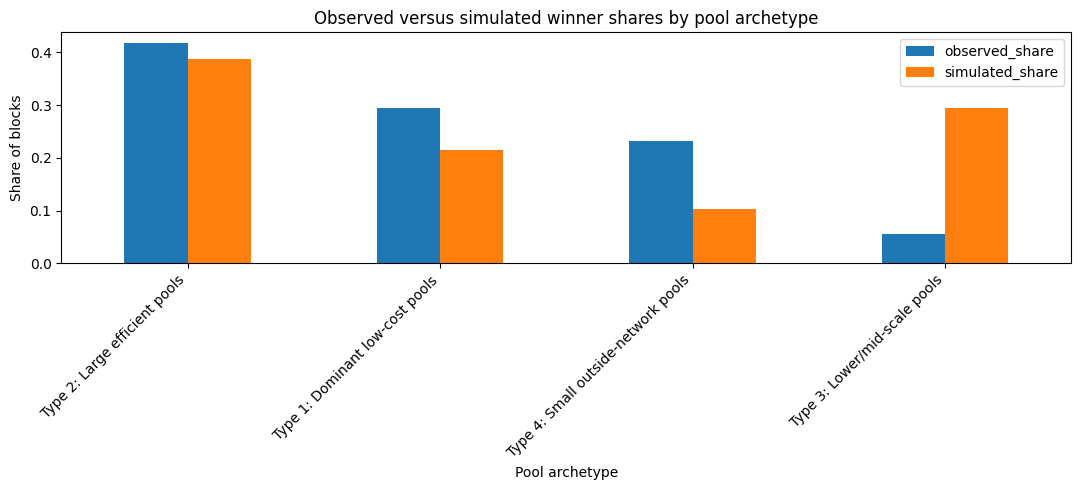

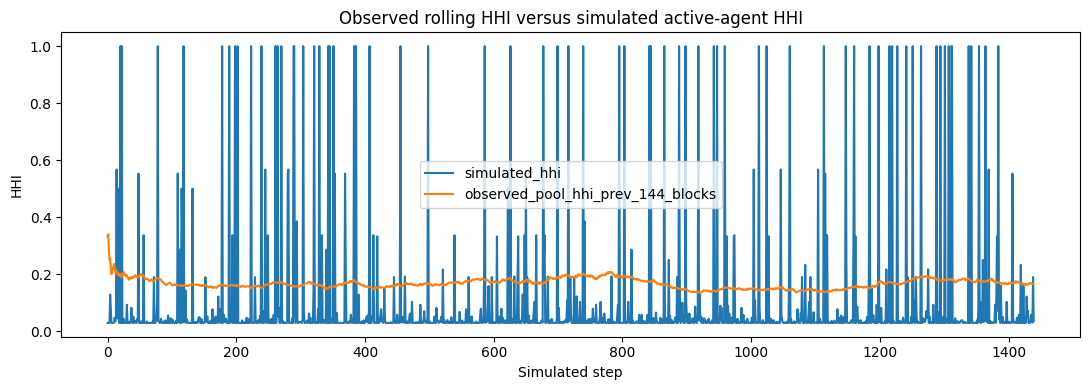

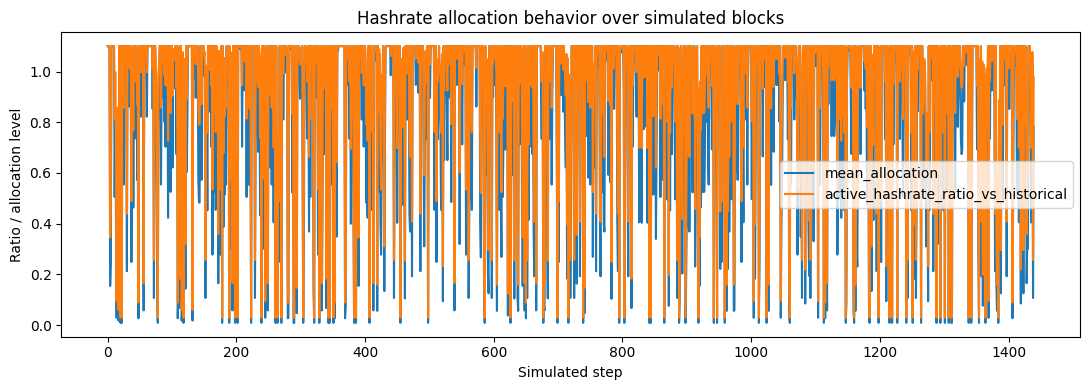

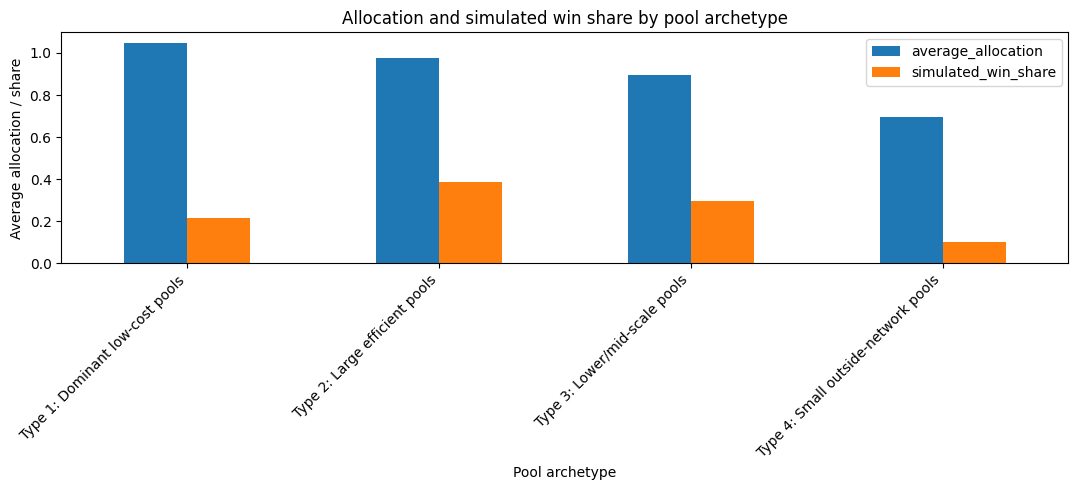

In [41]:
type_share_validation[["observed_share", "simulated_share"]].plot(kind="bar", figsize=(11, 5))
plt.title("Observed versus simulated winner shares by pool archetype")
plt.ylabel("Share of blocks")
plt.xlabel("Pool archetype")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

round_summary_df[["simulated_hhi", "observed_pool_hhi_prev_144_blocks"]].dropna().plot(figsize=(11, 4))
plt.title("Observed rolling HHI versus simulated active-agent HHI")
plt.ylabel("HHI")
plt.xlabel("Simulated step")
plt.tight_layout()
plt.show()

round_summary_df[["mean_allocation", "active_hashrate_ratio_vs_historical"]].plot(figsize=(11, 4))
plt.title("Hashrate allocation behavior over simulated blocks")
plt.ylabel("Ratio / allocation level")
plt.xlabel("Simulated step")
plt.tight_layout()
plt.show()

agent_type_summary_df.set_index("agent_type")[["average_allocation", "simulated_win_share"]].plot(kind="bar", figsize=(11, 5))
plt.title("Allocation and simulated win share by pool archetype")
plt.ylabel("Average allocation / share")
plt.xlabel("Pool archetype")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### 3.7 Export process-mining files

The event log can be used for process mining. The round and agent summaries are useful for simulation validation and dashboarding.

In [42]:
event_log_df.to_csv("MAS/bitcoin_agent_event_log_historical_playthrough_archetypes.csv", index=False)
round_summary_df.to_csv("MAS/bitcoin_agent_round_summary_historical_playthrough_archetypes.csv", index=False)
agent_summary_df.to_csv("MAS/bitcoin_agent_summary_historical_playthrough_archetypes.csv", index=False)
agent_type_summary_df.to_csv("MAS/bitcoin_agent_type_summary_historical_playthrough_archetypes.csv", index=False)

default_exports = [
    "MAS/bitcoin_agent_event_log_historical_playthrough_archetypes.csv",
    "MAS/bitcoin_agent_round_summary_historical_playthrough_archetypes.csv",
    "MAS/bitcoin_agent_summary_historical_playthrough_archetypes.csv",
    "MAS/bitcoin_agent_type_summary_historical_playthrough_archetypes.csv",
]

print("Saved:")
for export_file in default_exports:
    print(f"- {export_file}")


Saved:
- MAS/bitcoin_agent_event_log_historical_playthrough_archetypes.csv
- MAS/bitcoin_agent_round_summary_historical_playthrough_archetypes.csv
- MAS/bitcoin_agent_summary_historical_playthrough_archetypes.csv
- MAS/bitcoin_agent_type_summary_historical_playthrough_archetypes.csv


### 3.8 Interpretation and limitations

This version is stronger than the previous top-pool-only version because it explicitly models **heterogeneity between mining-pool archetypes**. The agents are no longer only different by name and size. They differ by:

- relative hashrate scale;
- electricity cost;
- hardware efficiency;
- archetype membership;
- resulting allocation behavior and profitability.

The model can now support counterfactual questions such as:

- Which archetype scales back first when electricity prices rise?
- Do low-cost dominant pools gain more win share when market conditions worsen?
- Does flexible hashrate allocation reduce losses for marginal pools?
- Does heterogeneous cost structure increase simulated concentration?

Important limitations:

- The 130 agents are synthetic archetype agents, not verified real-world organizations.
- The proposed hashrate bands are used as relative size scores and then normalized to the historical network hashrate.
- Observed block shares are only proxies for true pool hashrate.
- Electricity prices, hardware efficiency, and the allocation power curve are scenario assumptions, not observed variables.
- The model replays observed block intervals. If large parts of the network scale back endogenously, a more advanced model should let active hash power affect expected block time.
- The allocation rule is still myopic: pools choose the best allocation for the current block only. They do not yet learn, forecast price, sign energy contracts, or strategically react to competitors.
- This model validates aggregate behavior by archetype, not exact block-by-block prediction.

A natural next scenario extension would be to add endogenous block-time effects:

```text
expected_block_time_mins = 10 * historical_network_hashrate / simulated_active_hashrate
```

That extension should be kept separate from the historical validation model because it changes the simulated time path.


## 4. Process Mining 